# 每日最大异常成交量（ABNVOLD）

**行为金融因子 —— 投资者注意力**

$$
\text{ABNVOLD} = \max_{t} \left( \frac{VOL_{i,t}}{\overline{VOL}_{i,t}} \right)
$$

其中：

* $VOL_{i,t}$ 为股票 $i$ 在交易日 $t$ 的成交量；
* $\overline{VOL}_{i,t}$ 为股票 $i$ 在交易日 $t$ 滚动 1 年的平均成交量；
* $m$ 为交易日窗口，一般取为月度。

## 因子说明

每日最大异常成交量（ABNVOLD）为日频成交量除以过去一年平均成交量的最大值，属于**极端交易量类因子**。异常成交量是投资者注意力的常用代理指标之一。因子取值越高，表明该股票在当月曾出现过异常放量，投资者的关注度也就越高。然而，投资者的注意力是有限的，他们更倾向于交易那些引起自己注意的股票。通常情况下，关注度较高的股票会伴随更多的买入行为。但在 A 股市场中，由于**做多与做空机制不对称**，投资者非理性买入的倾向强于非理性卖出，导致高关注度股票因净买入力量而出现短期价格溢价，这种过度反应往往会在未来引发价格反转。

数据：成交量

分母只用前 250 日成交量，没有未来函数；随后取过去 20 日的最大异常成交量。若计算正确，新股至少要积累 250 + 20 - 1 = 269 个交易日历史，才应首次出现因子。因此不必另加 60 日上市过滤，但应重点检查是否有股票在上市不足 269 个交易日时就产生了因子值。当前把停牌日的零成交量计入一年均量。它不是代码错误，但会让长期停牌后复牌的股票更容易出现超高 ABNVOLD。先用下方代码检查；若极端值集中在复牌后，再决定是否改为“仅以有效交易日成交量计算均值”。

## OLD

In [1]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def calculate_abnvold_daily(
    start_date,
    end_date,
    short_window=20,
    long_window=250,
    candidate_ids=None,
    batch_size=500,
):
    """
    计算日频滚动每日最大异常成交量（ABNVOLD）。

    AVOL_i,t = VOL_i,t / mean(VOL_i,t-long_window ... VOL_i,t-1)

    ABNVOLD_i,T = max(AVOL_i,t), t 属于过去 short_window 个交易日

    返回
    ----
    DataFrame
        MultiIndex：date、order_book_id
        Column：ABNVOLD
    """
    # 第一个输出日 T：
    # 其短窗口最早日为 T-(short_window-1)，
    # 该日还需要再向前 long_window 天来估计平均成交量。
    required_lookback = long_window + short_window - 1

    target_dates, volume_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=required_lookback,
    )

    candidate_ids = _get_ids(candidate_ids)
    factor_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        # 复用已有辅助函数；这里只使用其中的 volume。
        _, volume = _get_batch_close_volume(batch, volume_dates)

        if volume is None:
            continue

        # 不使用当天成交量作为当天的“正常成交量”基准。
        average_volume = (
            volume.rolling(
                window=long_window,
                min_periods=long_window,
            )
            .mean()
            .shift(1)
        )

        # 停牌或无成交日不计入有效异常成交量观测。
        abnormal_volume = (
            volume.div(average_volume)
            .where(volume.gt(0))
        )

        # 每个 T 日取过去 short_window 日的最大异常成交量。
        factor_wide = abnormal_volume.rolling(
            window=short_window,
            min_periods=short_window,
        ).max()

        factor_wide = factor_wide.reindex(target_dates)

        factor_parts.append(
            _stack_factor(factor_wide, "ABNVOLD")
        )

    if not factor_parts:
        return pd.DataFrame(columns=["ABNVOLD"])

    return pd.concat(factor_parts).sort_index()

In [2]:
def exclude_recent_listings(raw_df, min_trading_days=60):
    """剔除上市未满指定交易日的股票因子值。

    以股票上市日为第 0 个交易日；当其后的 ``min_trading_days`` 个交易日均已
    过去，才保留因子。例如 ``min_trading_days=60`` 时，上市后的第 61 个交易日
    起才允许计算因子值。该规则可避免新股上市初期的无涨跌幅限制波动主导排序。

    本函数只过滤最终因子面板；因此可以直接接在
    ``calculate_...(...)`` 后使用。
    """
    if min_trading_days < 0:
        raise ValueError("min_trading_days 不能为负数。")
    if not isinstance(raw_df.index, pd.MultiIndex) or raw_df.index.nlevels != 2:
        raise ValueError("索引必须为两层 MultiIndex：(date, order_book_id)。")

    # 延迟导入，使单纯的数据检查不依赖已初始化的 rqdatac。
    from rqdatac import all_instruments, get_trading_dates

    panel = raw_df.copy()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    signal_dates = pd.DatetimeIndex(panel.index.get_level_values("date"))
    stock_ids = pd.Index(panel.index.get_level_values("order_book_id").unique())

    instruments_df = all_instruments("CS").set_index("order_book_id")
    listed_dates = pd.to_datetime(
        instruments_df["listed_date"].reindex(stock_ids), errors="coerce"
    )
    if listed_dates.isna().any():
        missing_ids = listed_dates[listed_dates.isna()].index.tolist()[:10]
        raise ValueError("以下股票缺少 listed_date：{}".format(missing_ids))

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=signal_dates.max(),
        )
    )
    listing_locs = calendar.searchsorted(listed_dates.to_numpy(), side="left")
    eligible_locs = listing_locs + min_trading_days

    eligible_from_values = np.full(
        len(stock_ids), np.datetime64("NaT"), dtype="datetime64[ns]"
    )
    within_calendar = eligible_locs < len(calendar)
    eligible_from_values[within_calendar] = calendar.to_numpy()[eligible_locs[within_calendar]]
    eligible_from = pd.Series(pd.to_datetime(eligible_from_values), index=stock_ids)

    row_ids = panel.index.get_level_values("order_book_id")
    row_eligible_from = eligible_from.reindex(row_ids).to_numpy()
    keep = signal_dates.to_numpy() >= row_eligible_from
    return panel.loc[keep].sort_index()

In [3]:
abnvold_panel = calculate_abnvold_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    short_window=20,  # 月度最大值窗口
    long_window=250,  # 一年平均成交量窗口
)

abnvold_panel.head()

ABNVOLD
date       order_book_id          
2020-01-02 000001.XSHE    1.515005
           000002.XSHE    3.804247
           000004.XSHE    3.314422
           000005.XSHE    1.094616
           000006.XSHE    1.345867

,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
实际有效观测数,6.335590e+06,
覆盖股票数,5.288000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0
负值,0.000000e+00,应为 0



最近 5 个交易日的横截面统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,年份,相对覆盖率
date,,,,,,,,,,,,
2025-12-25,5015,2.104536,1.834868,0.208396,1.516613,20.96511,0.378221,0.541221,5.836083,9.176407,2025,0.996028
2025-12-26,5017,2.122024,1.854221,0.208396,1.536502,20.96511,0.381056,0.547983,5.854184,9.163106,2025,0.996425
2025-12-29,5017,2.133838,1.863078,0.208396,1.538051,20.96511,0.381056,0.545966,5.861711,9.163106,2025,0.996425
2025-12-30,5020,2.140040,1.854957,0.208396,1.553714,20.96511,0.381066,0.548969,5.852746,9.154380,2025,0.997021
2025-12-31,5019,2.130807,1.814260,0.208396,1.560860,20.96511,0.387457,0.550198,5.773220,8.878364,2025,0.996822



因子值最大的 20 条记录：


,date,order_book_id,ABNVOLD
570860,2020-09-02,300216.XSHE,100750.000000
2184780,2022-06-02,002260.XSHE,29650.397513
2218048,2022-06-15,002260.XSHE,29650.397513
2197225,2022-06-08,002260.XSHE,29650.397513
2201382,2022-06-09,002260.XSHE,29650.397513
2193073,2022-06-07,002260.XSHE,29650.397513
2213879,2022-06-14,002260.XSHE,29650.397513
2222223,2022-06-16,002260.XSHE,29650.397513
2188925,2022-06-06,002260.XSHE,29650.397513
2205544,2022-06-10,002260.XSHE,29650.397513


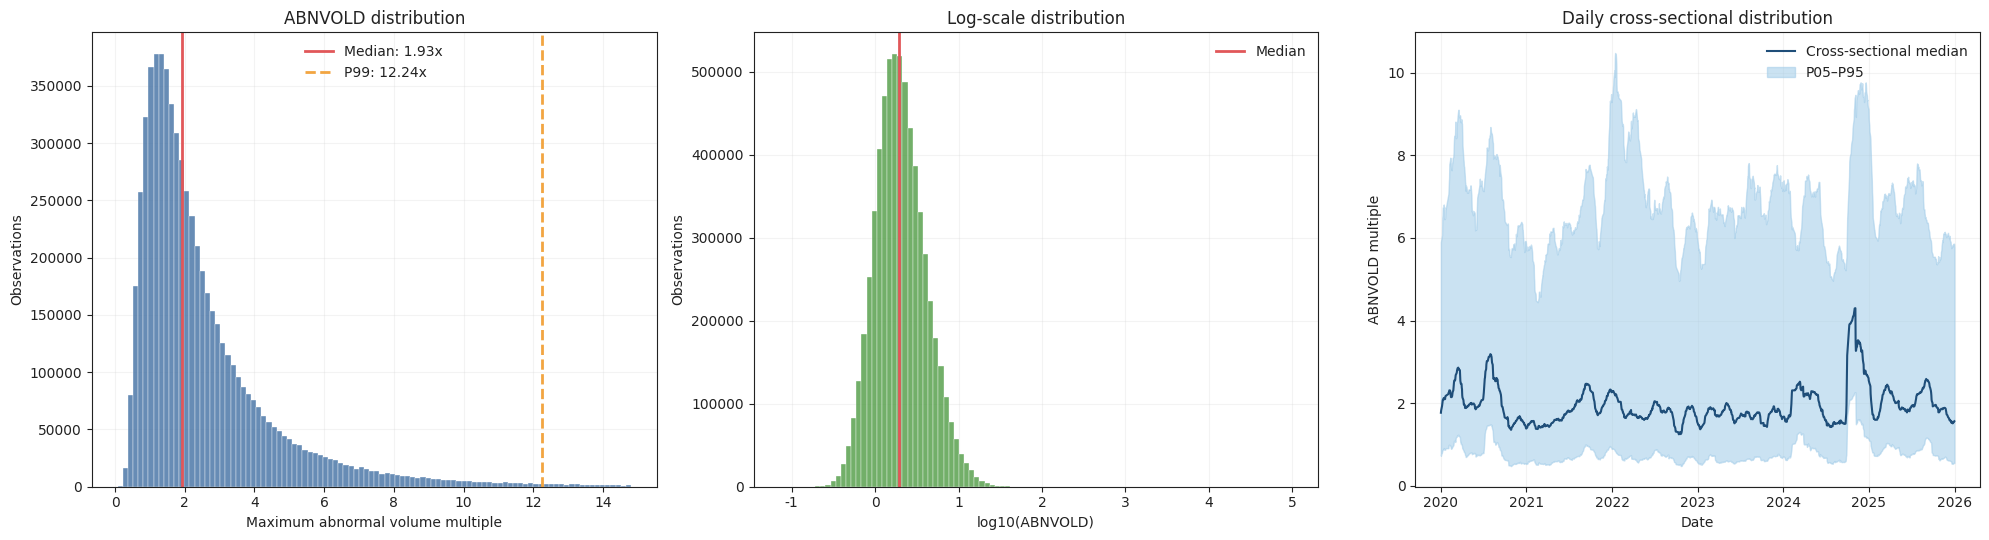

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from rqdatac import all_instruments, get_trading_dates

FACTOR_NAME = "ABNVOLD"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"

SHORT_WINDOW = 20
LONG_WINDOW = 250
REQUIRED_HISTORY = LONG_WINDOW + SHORT_WINDOW - 1

panel = abnvold_panel.copy()

# ---------- 1. 基础结构与数值完整性 ----------
if not isinstance(panel.index, pd.MultiIndex):
    raise ValueError("abnvold_panel 应为 date、order_book_id 两层 MultiIndex。")

if FACTOR_NAME not in panel.columns:
    raise ValueError("未找到因子列：{}".format(FACTOR_NAME))

if "date" not in panel.index.names or "order_book_id" not in panel.index.names:
    raise ValueError("MultiIndex 名称应为 date、order_book_id。")

check_data = pd.DataFrame({
    "date": pd.to_datetime(panel.index.get_level_values("date")),
    "order_book_id": panel.index.get_level_values("order_book_id"),
    FACTOR_NAME: pd.to_numeric(panel[FACTOR_NAME], errors="coerce").values,
})

expected_dates = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=START_DATE,
            end_date=END_DATE,
        )
    )
)

raw_value = check_data[FACTOR_NAME]
is_finite = pd.Series(
    np.isfinite(raw_value.values),
    index=check_data.index,
)
is_positive = raw_value > 0
is_valid = is_finite & is_positive

valid = check_data.loc[is_valid].copy()

# ---------- 2. 每日覆盖与横截面分布 ----------
daily = valid.groupby("date")[FACTOR_NAME].agg(
    ["count", "mean", "std", "min", "median", "max"]
)
daily.columns = ["因子股票数", "均值", "标准差", "最小值", "中位数", "最大值"]

daily["P01"] = valid.groupby("date")[FACTOR_NAME].quantile(0.01)
daily["P05"] = valid.groupby("date")[FACTOR_NAME].quantile(0.05)
daily["P95"] = valid.groupby("date")[FACTOR_NAME].quantile(0.95)
daily["P99"] = valid.groupby("date")[FACTOR_NAME].quantile(0.99)

daily = daily.reindex(expected_dates)
daily.index.name = "date"
daily["因子股票数"] = daily["因子股票数"].fillna(0)

daily["年份"] = daily.index.year
year_max_count = daily.groupby("年份")["因子股票数"].transform("max")
daily["相对覆盖率"] = (
    daily["因子股票数"]
    / year_max_count.replace(0, np.nan)
)

stock_days = valid.groupby("order_book_id").size()

# ---------- 3. 首次输出日期：检查是否过早使用了新股数据 ----------
first_factor_date = valid.groupby("order_book_id")["date"].min()

instruments_df = (
    all_instruments("CS")
    .drop_duplicates("order_book_id")
    .set_index("order_book_id")
)

listed_dates = pd.to_datetime(
    instruments_df["listed_date"].reindex(first_factor_date.index),
    errors="coerce",
)

calendar = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=END_DATE,
        )
    )
)

listing_locs = calendar.searchsorted(listed_dates.values, side="left")
first_factor_locs = calendar.searchsorted(
    first_factor_date.values,
    side="left",
)

history_age = pd.Series(
    first_factor_locs - listing_locs,
    index=first_factor_date.index,
    name="首次因子值时距上市交易日数",
)

early_factor_stocks = history_age[
    history_age < REQUIRED_HISTORY
].sort_values()

# ---------- 4. 汇总 ----------
summary = pd.DataFrame([
    ["目标交易日数", len(expected_dates), ""],
    ["有至少一个因子值的交易日数", int((daily["因子股票数"] > 0).sum()),
     "应接近目标交易日数"],
    ["完全无输出交易日数", int((daily["因子股票数"] == 0).sum()),
     "应为 0"],
    ["实际有效观测数", len(valid), ""],
    ["覆盖股票数", valid["order_book_id"].nunique(), ""],
    ["重复 date-stock", int(check_data.duplicated(["date", "order_book_id"]).sum()),
     "应为 0"],
    ["显式缺失值", int(raw_value.isna().sum()),
     "最终 stack 后通常应为 0"],
    ["无穷值（inf/-inf）", int(np.isinf(raw_value.values).sum()),
     "应为 0"],
    ["负值", int((raw_value < 0).sum()),
     "应为 0"],
    ["零值", int((raw_value == 0).sum()),
     "应为 0；有成交日的成交量比值应为正"],
    ["每日因子股票数均值", daily["因子股票数"].mean(), ""],
    ["每日因子股票数 P05", daily["因子股票数"].quantile(0.05),
     "检查低覆盖交易日"],
    ["相对覆盖率 P05", daily["相对覆盖率"].quantile(0.05),
     "建议大于 0.80"],
    ["单股有效天数 P05", stock_days.quantile(0.05),
     "新股、停牌股或退市股通常较低"],
    ["上市不足 {} 个交易日即出现因子的股票数".format(REQUIRED_HISTORY),
     len(early_factor_stocks),
     "应为 0"],
    ["因子均值", valid[FACTOR_NAME].mean(), ""],
    ["因子标准差", valid[FACTOR_NAME].std(), ""],
    ["最小值", valid[FACTOR_NAME].min(),
     "应大于 0；小于 1 并不一定错误"],
    ["P01", valid[FACTOR_NAME].quantile(0.01), ""],
    ["中位数", valid[FACTOR_NAME].median(),
     "可理解为过去 20 日内的典型最大放量倍数"],
    ["P99", valid[FACTOR_NAME].quantile(0.99),
     "检查右尾放量股票"],
    ["最大值", valid[FACTOR_NAME].max(),
     "需复核复牌、低流动性或公司事件"],
    ["> 10 倍的观测数", int((valid[FACTOR_NAME] > 10).sum()),
     "人工复核阈值"],
    ["> 20 倍的观测数", int((valid[FACTOR_NAME] > 20).sum()),
     "人工复核阈值"],
    ["> 50 倍的观测数", int((valid[FACTOR_NAME] > 50).sum()),
     "优先检查是否集中于复牌或极低流动性股票"],
], columns=["指标", "数值", "判断"])

display(summary.set_index("指标"))

print("\n最近 5 个交易日的横截面统计：")
display(daily.tail())

print("\n因子值最大的 20 条记录：")
top20 = valid.sort_values(FACTOR_NAME, ascending=False).head(20)
display(top20[["date", "order_book_id", FACTOR_NAME]])

if len(early_factor_stocks) > 0:
    print("\n上市历史不足 {} 个交易日就出现因子的股票：".format(REQUIRED_HISTORY))
    display(early_factor_stocks.head(20).to_frame())

# ---------- 5. 分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
    "axes.unicode_minus": False,
})

plot_upper = valid[FACTOR_NAME].quantile(0.995)
plot_values = valid.loc[
    valid[FACTOR_NAME] <= plot_upper,
    FACTOR_NAME,
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# 原始倍数分布：仅显示至 P99.5，防止极端值压缩主体
axes[0].hist(
    plot_values,
    bins=100,
    color="#4C78A8",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[0].axvline(
    valid[FACTOR_NAME].median(),
    color="#E15759",
    linewidth=2,
    label="Median: {:.2f}x".format(valid[FACTOR_NAME].median()),
)
axes[0].axvline(
    valid[FACTOR_NAME].quantile(0.99),
    color="#F2A541",
    linewidth=2,
    linestyle="--",
    label="P99: {:.2f}x".format(valid[FACTOR_NAME].quantile(0.99)),
)
axes[0].set_title("ABNVOLD distribution")
axes[0].set_xlabel("Maximum abnormal volume multiple")
axes[0].set_ylabel("Observations")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 对数分布：完整展示右尾
axes[1].hist(
    np.log10(valid[FACTOR_NAME]),
    bins=100,
    color="#59A14F",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[1].axvline(
    np.log10(valid[FACTOR_NAME].median()),
    color="#E15759",
    linewidth=2,
    label="Median",
)
axes[1].set_title("Log-scale distribution")
axes[1].set_xlabel("log10(ABNVOLD)")
axes[1].set_ylabel("Observations")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

# 每日横截面分布
plot_daily = daily.dropna(subset=["P05", "中位数", "P95"])

axes[2].fill_between(
    plot_daily.index,
    plot_daily["P05"].values,
    plot_daily["P95"].values,
    color="#A0CBE8",
    alpha=0.55,
    label="P05–P95",
)
axes[2].plot(
    plot_daily.index,
    plot_daily["中位数"].values,
    color="#1F4E79",
    linewidth=1.5,
    label="Cross-sectional median",
)
axes[2].set_title("Daily cross-sectional distribution")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("ABNVOLD multiple")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.25)
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.show()

完整性通过，但数值合理性在极端尾部**未通过最终验收**。

主体分布是正常的：

- 全部 1,455 个交易日均有输出；
- 无重复、缺失、无穷值、负值或零值；
- 没有股票在上市不足 269 个交易日时产生因子；
- 中位数 `1.93` 倍、P99 `12.24` 倍，2025 年末中位数约 `1.5` 倍、P99 约 `9` 倍，均属合理范围；
- 同一极端值连续出现，是 20 日滚动最大值保留前期放量峰值的正常现象。

但最大值 `100,750` 倍、`29,650` 倍、`19,641` 倍过于极端。它们导致标准差高达 `65.90`，而 P99 只有 `12.24`，说明极少数观测严重拉长右尾。数学上未必错误，但不适合直接用于横截面排序、标准化或回测。

优先检查这些极端值是否由“长期停牌/极低成交量后突然放量”造成。下面代码会严格复现你的分母和 20 日最大值逻辑，并找出因子日期对应的实际异常成交日。若输出显示这些股票此前 250 日内大量 `volume=0`，或 `average_volume_250d` 极低，则应将分母改为“过去一年有效交易日的平均成交量”，并要求至少例如 200 个活跃交易日；这能避免停牌复牌型放量主导 ABNVOLD。若分母正常、但确有持续极低成交后巨幅放量，则保留原始因子，但在使用前按日做 0.5%–99.5% 缩尾。

In [5]:
from rqdatac import get_price, get_trading_dates

def inspect_abnvold_extreme(stock_id, factor_date,
                            long_window=250,
                            short_window=20):
    factor_date = pd.Timestamp(factor_date)
    start_date = factor_date - pd.Timedelta(days=550)

    trade_dates = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(
                start_date=start_date,
                end_date=factor_date,
            )
        )
    )

    raw = get_price(
        order_book_ids=stock_id,
        start_date=trade_dates[0],
        end_date=trade_dates[-1],
        frequency="1d",
        fields=["volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if isinstance(raw.index, pd.MultiIndex):
        raw = raw.reset_index()
        raw["date"] = pd.to_datetime(raw["date"])
        raw = raw.set_index("date")

    raw.index = pd.to_datetime(raw.index)
    volume = raw["volume"].reindex(trade_dates)

    average_volume = (
        volume.rolling(
            window=long_window,
            min_periods=long_window,
        )
        .mean()
        .shift(1)
    )

    abnormal_volume = (
        volume.div(average_volume)
        .where(volume.gt(0))
    )

    reproduced_factor = abnormal_volume.rolling(
        window=short_window,
        min_periods=short_window,
    ).max()

    result = pd.DataFrame({
        "volume": volume,
        "average_volume_250d": average_volume,
        "single_day_abnormal_volume": abnormal_volume,
        "ABNVOLD_reproduced": reproduced_factor,
    })

    last_window = result.loc[:factor_date].tail(short_window)
    peak_date = last_window["single_day_abnormal_volume"].idxmax()

    print("因子日期：{}".format(factor_date.date()))
    print("20 日窗口内实际异常成交量峰值日期：{}".format(peak_date.date()))
    print("复现的 ABNVOLD：{:.6f}".format(
        reproduced_factor.loc[factor_date]
    ))

    print("\n因子日期前的 20 日窗口：")
    display(last_window)

    print("\n实际峰值日前后 10 个交易日：")
    display(result.loc[:peak_date].tail(10))

    return result

inspect_abnvold_extreme("300216.XSHE", "2020-09-02")
inspect_abnvold_extreme("002260.XSHE", "2022-06-02")
inspect_abnvold_extreme("000760.XSHE", "2021-07-13")

因子日期：2020-09-02
20 日窗口内实际异常成交量峰值日期：2020-08-06
复现的 ABNVOLD：100750.000000

因子日期前的 20 日窗口：


,volume,average_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2020-08-06,40300.0,0.4,100750.000000,NaN
2020-08-07,200.0,161.6,1.237624,NaN
2020-08-10,100.0,162.4,0.615764,NaN
2020-08-11,2000.0,162.8,12.285012,NaN
2020-08-12,100.0,170.8,0.585480,NaN
2020-08-13,17800.0,171.2,103.971963,NaN
2020-08-14,100.0,242.4,0.412541,NaN
2020-08-17,100.0,242.8,0.411862,NaN
2020-08-18,200.0,243.2,0.822368,NaN
2020-08-19,10100.0,244.0,41.393443,NaN



实际峰值日前后 10 个交易日：


,volume,average_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2020-07-24,0.0,0.0,NaN,NaN
2020-07-27,0.0,0.0,NaN,NaN
2020-07-28,0.0,0.0,NaN,NaN
2020-07-29,0.0,0.0,NaN,NaN
2020-07-30,0.0,0.0,NaN,NaN
2020-07-31,0.0,0.0,NaN,NaN
2020-08-03,0.0,0.0,NaN,NaN
2020-08-04,0.0,0.0,NaN,NaN
2020-08-05,100.0,0.0,inf,NaN
2020-08-06,40300.0,0.4,100750.0,NaN


因子日期：2022-06-02
20 日窗口内实际异常成交量峰值日期：2022-05-24
复现的 ABNVOLD：29650.397513

因子日期前的 20 日窗口：


...

因子日期：2021-07-13
20 日窗口内实际异常成交量峰值日期：2021-07-02
复现的 ABNVOLD：19641.289394

因子日期前的 20 日窗口：


,volume,average_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2021-06-16,15300.0,403.600,37.908821,NaN
2021-06-17,16100.0,464.800,34.638554,NaN
2021-06-18,400.0,529.200,0.755858,NaN
2021-06-21,500.0,530.800,0.941974,NaN
2021-06-22,4400.0,532.800,8.258258,NaN
2021-06-23,3300.0,550.400,5.995640,NaN
2021-06-24,59100.0,563.600,104.861604,NaN
2021-06-25,70700.0,800.000,88.375000,NaN
2021-06-28,139500.0,1082.800,128.832656,NaN
2021-06-29,89500.0,1640.800,54.546563,NaN



实际峰值日前后 10 个交易日：


,volume,average_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2021-06-21,500.0,530.8,0.941974,NaN
2021-06-22,4400.0,532.8,8.258258,NaN
2021-06-23,3300.0,550.4,5.995640,NaN
2021-06-24,59100.0,563.6,104.861604,NaN
2021-06-25,70700.0,800.0,88.375000,NaN
2021-06-28,139500.0,1082.8,128.832656,NaN
2021-06-29,89500.0,1640.8,54.546563,NaN
2021-06-30,306500.0,1998.8,153.342005,NaN
2021-07-01,678800.0,3224.8,210.493674,NaN
2021-07-02,116669259.0,5940.0,19641.289394,NaN


,volume,average_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2020-01-10,26503746.0,NaN,NaN,NaN
2020-01-13,28144752.0,NaN,NaN,NaN
2020-01-14,19308901.0,NaN,NaN,NaN
2020-01-15,17078076.0,NaN,NaN,NaN
2020-01-16,23947938.0,NaN,NaN,NaN
...,...,...,...,...
2021-07-07,47836765.0,934595.376,51.184466,NaN
2021-07-08,26142254.0,1125942.436,23.218109,19641.289394
2021-07-09,20199667.0,1230511.452,16.415668,19641.289394
2021-07-12,34981745.0,1311310.120,26.676943,19641.289394


结论明确：这些极端值来自**长期零成交/停牌后突然恢复大额成交**，而不是正常的“异常放量”。

例如：

- `300216.XSHE` 在 2020-08-06 的 250 日均量仅 `0.4`，当天成交量 `40,300`，得到 `100,750` 倍；
- `002260.XSHE` 在 2022-05-24 的均量仅 `2,862.8`，当天成交量 `84,883,158`，得到 `29,650` 倍；
- `000760.XSHE` 在 2021-07-02 的均量仅 `5,940`，当天成交量 `116,669,259`，得到 `19,641` 倍。

更关键的是，`300216.XSHE` 在 2020-08-05 已产生了 `volume / average_volume = inf`。虽然它恰好没有进入最终因子面板，但说明当前分母会被停牌日的零成交量严重稀释。

因此，不建议直接对当前结果缩尾后使用；应先修正分母口径：仅用过去一年中的有效成交日计算平均成交量，并要求过去 250 个交易日中至少有 200 个有效成交日。

在 `calculate_abnvold_daily` 的参数中加入：

```python
min_active_days=200,
```

并用下面代码替换原来的 `average_volume` 与 `abnormal_volume` 部分：

```python
if min_active_days <= 0 or min_active_days > long_window:
    raise ValueError("min_active_days 必须介于 1 和 long_window 之间。")

# 仅保留实际有成交的日成交量。
active_volume = volume.where(volume.gt(0))

# 过去 long_window 个市场交易日中，实际有成交的天数。
active_count = (
    volume.gt(0)
    .rolling(
        window=long_window,
        min_periods=long_window,
    )
    .sum()
    .shift(1)
)

# 过去一年有效成交日的平均成交量，不让停牌日的 0 稀释分母。
active_volume_sum = (
    active_volume.rolling(
        window=long_window,
        min_periods=1,
    )
    .sum()
    .shift(1)
)

average_volume = active_volume_sum.div(
    active_count.where(active_count >= min_active_days)
)

# 分子、分母均有效时才计算，彻底避免 inf。
abnormal_volume = (
    volume.div(average_volume)
    .where(
        volume.gt(0)
        & average_volume.gt(0)
    )
)
```

重新计算后，建议再补一层上市历史过滤，确保新股也有完整的一年基准：

```python
abnvold_panel = calculate_abnvold_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    short_window=20,
    long_window=250,
    min_active_days=200,
)

abnvold_panel = exclude_recent_listings(
    abnvold_panel,
    min_trading_days=269,
)
```

之后用刚才的检查与分布图代码重新验证。预期最大值会显著下降、均值与标准差会更接近中位数和 P99 所反映的主体分布。

## NEW

In [6]:
def calculate_abnvold_daily(
    start_date,
    end_date,
    short_window=20,
    long_window=250,
    candidate_ids=None,
    batch_size=500,
    min_active_days=200
):
    """
    计算日频滚动每日最大异常成交量（ABNVOLD）。

    AVOL_i,t = VOL_i,t / mean(VOL_i,t-long_window ... VOL_i,t-1)

    ABNVOLD_i,T = max(AVOL_i,t), t 属于过去 short_window 个交易日

    返回
    ----
    DataFrame
        MultiIndex：date、order_book_id
        Column：ABNVOLD
    """
    # 第一个输出日 T：
    # 其短窗口最早日为 T-(short_window-1)，
    # 该日还需要再向前 long_window 天来估计平均成交量。
    required_lookback = long_window + short_window - 1

    target_dates, volume_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=required_lookback,
    )

    candidate_ids = _get_ids(candidate_ids)
    factor_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        # 复用已有辅助函数；这里只使用其中的 volume。
        _, volume = _get_batch_close_volume(batch, volume_dates)

        if volume is None:
            continue

        if min_active_days <= 0 or min_active_days > long_window:
            raise ValueError("min_active_days 必须介于 1 和 long_window 之间。")

        # 仅保留实际有成交的日成交量。
        active_volume = volume.where(volume.gt(0))

        # 过去 long_window 个市场交易日中，实际有成交的天数。
        active_count = (
            volume.gt(0)
            .rolling(
                window=long_window,
                min_periods=long_window,
            )
            .sum()
            .shift(1)
        )

        # 过去一年有效成交日的平均成交量，不让停牌日的 0 稀释分母。
        active_volume_sum = (
            active_volume.rolling(
                window=long_window,
                min_periods=1,
            )
            .sum()
            .shift(1)
        )

        average_volume = active_volume_sum.div(
            active_count.where(active_count >= min_active_days)
        )

        # 分子、分母均有效时才计算，彻底避免 inf。
        abnormal_volume = (
            volume.div(average_volume)
            .where(
                volume.gt(0)
                & average_volume.gt(0)
            )
        )

        # 每个 T 日取过去 short_window 日的最大异常成交量。
        factor_wide = abnormal_volume.rolling(
            window=short_window,
            min_periods=short_window,
        ).max()

        factor_wide = factor_wide.reindex(target_dates)

        factor_parts.append(
            _stack_factor(factor_wide, "ABNVOLD")
        )

    if not factor_parts:
        return pd.DataFrame(columns=["ABNVOLD"])

    return pd.concat(factor_parts).sort_index()

In [7]:
abnvold_panel = calculate_abnvold_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    short_window=20,
    long_window=250,
    min_active_days=200,
)

abnvold_panel = exclude_recent_listings(
    abnvold_panel,
    min_trading_days=269,
)

In [8]:
abnvold_panel.head()

ABNVOLD
date       order_book_id          
2020-01-02 000001.XSHE    1.515005
           000002.XSHE    3.804247
           000004.XSHE    3.168588
           000005.XSHE    1.094616
           000006.XSHE    1.345867

,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
实际有效观测数,6.334006e+06,
覆盖股票数,5.279000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0
负值,0.000000e+00,应为 0



最近 5 个交易日的横截面统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,年份,相对覆盖率
date,,,,,,,,,,,,
2025-12-25,5015,2.101014,1.832302,0.208396,1.516289,20.96511,0.378089,0.534042,5.814372,9.176407,2025,0.996028
2025-12-26,5017,2.118382,1.851523,0.208396,1.534997,20.96511,0.380250,0.546714,5.835706,9.163106,2025,0.996425
2025-12-29,5017,2.130237,1.860461,0.208396,1.537514,20.96511,0.380250,0.542414,5.853447,9.163106,2025,0.996425
2025-12-30,5020,2.136318,1.852260,0.208396,1.552009,20.96511,0.380466,0.548855,5.830880,9.154380,2025,0.997021
2025-12-31,5019,2.127154,1.811723,0.208396,1.557729,20.96511,0.387058,0.550198,5.769205,8.878364,2025,0.996822



因子值最大的 20 条记录：


,date,order_book_id,ABNVOLD
151514,2020-03-11,002062.XSHE,69.424572
183305,2020-03-24,002062.XSHE,69.424572
162116,2020-03-16,002062.XSHE,69.424572
190360,2020-03-26,002062.XSHE,69.424572
144445,2020-03-09,002062.XSHE,69.424572
204466,2020-04-01,002062.XSHE,69.424572
197416,2020-03-30,002062.XSHE,69.424572
165649,2020-03-17,002062.XSHE,69.424572
147979,2020-03-10,002062.XSHE,69.424572
172716,2020-03-19,002062.XSHE,69.424572


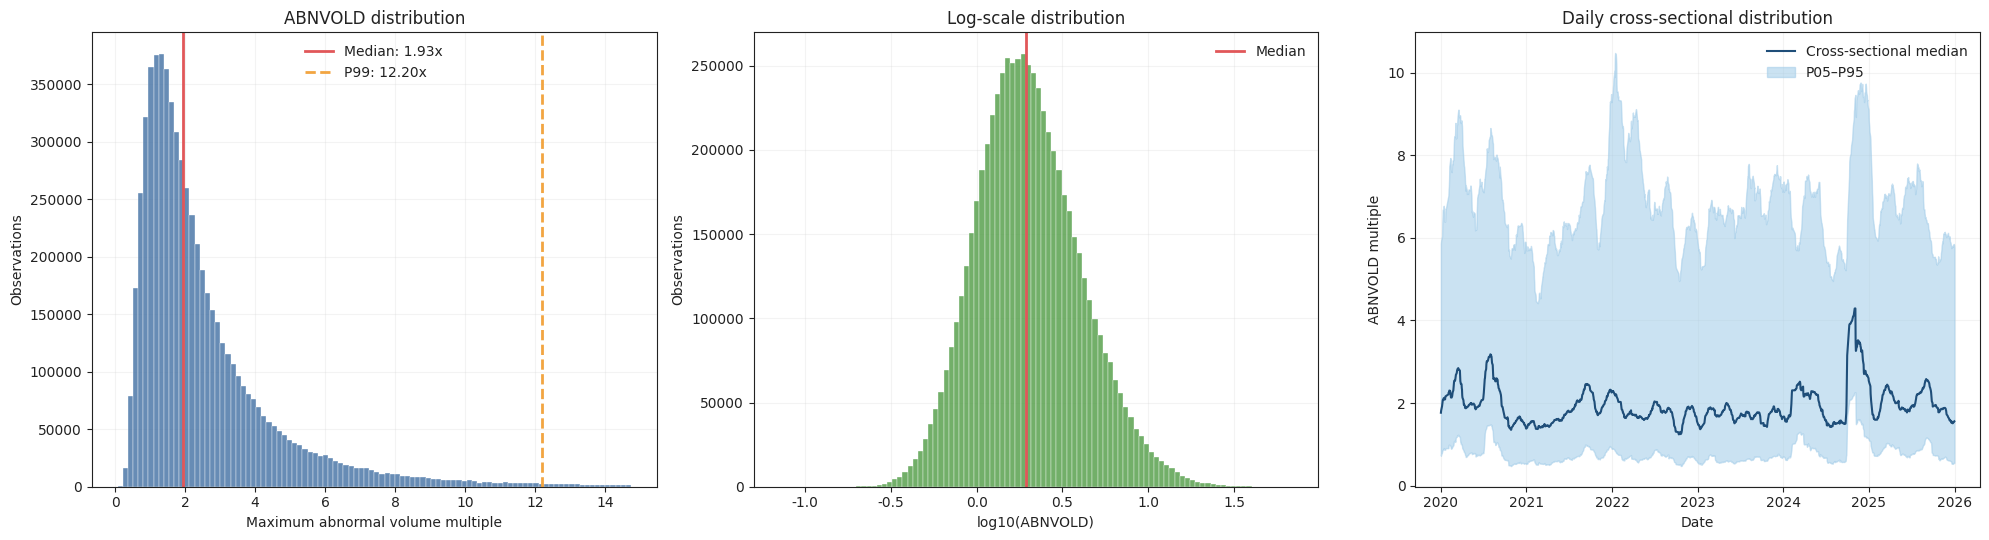

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from rqdatac import all_instruments, get_trading_dates

FACTOR_NAME = "ABNVOLD"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"

SHORT_WINDOW = 20
LONG_WINDOW = 250
REQUIRED_HISTORY = LONG_WINDOW + SHORT_WINDOW - 1

panel = abnvold_panel.copy()

# ---------- 1. 基础结构与数值完整性 ----------
if not isinstance(panel.index, pd.MultiIndex):
    raise ValueError("abnvold_panel 应为 date、order_book_id 两层 MultiIndex。")

if FACTOR_NAME not in panel.columns:
    raise ValueError("未找到因子列：{}".format(FACTOR_NAME))

if "date" not in panel.index.names or "order_book_id" not in panel.index.names:
    raise ValueError("MultiIndex 名称应为 date、order_book_id。")

check_data = pd.DataFrame({
    "date": pd.to_datetime(panel.index.get_level_values("date")),
    "order_book_id": panel.index.get_level_values("order_book_id"),
    FACTOR_NAME: pd.to_numeric(panel[FACTOR_NAME], errors="coerce").values,
})

expected_dates = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=START_DATE,
            end_date=END_DATE,
        )
    )
)

raw_value = check_data[FACTOR_NAME]
is_finite = pd.Series(
    np.isfinite(raw_value.values),
    index=check_data.index,
)
is_positive = raw_value > 0
is_valid = is_finite & is_positive

valid = check_data.loc[is_valid].copy()

# ---------- 2. 每日覆盖与横截面分布 ----------
daily = valid.groupby("date")[FACTOR_NAME].agg(
    ["count", "mean", "std", "min", "median", "max"]
)
daily.columns = ["因子股票数", "均值", "标准差", "最小值", "中位数", "最大值"]

daily["P01"] = valid.groupby("date")[FACTOR_NAME].quantile(0.01)
daily["P05"] = valid.groupby("date")[FACTOR_NAME].quantile(0.05)
daily["P95"] = valid.groupby("date")[FACTOR_NAME].quantile(0.95)
daily["P99"] = valid.groupby("date")[FACTOR_NAME].quantile(0.99)

daily = daily.reindex(expected_dates)
daily.index.name = "date"
daily["因子股票数"] = daily["因子股票数"].fillna(0)

daily["年份"] = daily.index.year
year_max_count = daily.groupby("年份")["因子股票数"].transform("max")
daily["相对覆盖率"] = (
    daily["因子股票数"]
    / year_max_count.replace(0, np.nan)
)

stock_days = valid.groupby("order_book_id").size()

# ---------- 3. 首次输出日期：检查是否过早使用了新股数据 ----------
first_factor_date = valid.groupby("order_book_id")["date"].min()

instruments_df = (
    all_instruments("CS")
    .drop_duplicates("order_book_id")
    .set_index("order_book_id")
)

listed_dates = pd.to_datetime(
    instruments_df["listed_date"].reindex(first_factor_date.index),
    errors="coerce",
)

calendar = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=END_DATE,
        )
    )
)

listing_locs = calendar.searchsorted(listed_dates.values, side="left")
first_factor_locs = calendar.searchsorted(
    first_factor_date.values,
    side="left",
)

history_age = pd.Series(
    first_factor_locs - listing_locs,
    index=first_factor_date.index,
    name="首次因子值时距上市交易日数",
)

early_factor_stocks = history_age[
    history_age < REQUIRED_HISTORY
].sort_values()

# ---------- 4. 汇总 ----------
summary = pd.DataFrame([
    ["目标交易日数", len(expected_dates), ""],
    ["有至少一个因子值的交易日数", int((daily["因子股票数"] > 0).sum()),
     "应接近目标交易日数"],
    ["完全无输出交易日数", int((daily["因子股票数"] == 0).sum()),
     "应为 0"],
    ["实际有效观测数", len(valid), ""],
    ["覆盖股票数", valid["order_book_id"].nunique(), ""],
    ["重复 date-stock", int(check_data.duplicated(["date", "order_book_id"]).sum()),
     "应为 0"],
    ["显式缺失值", int(raw_value.isna().sum()),
     "最终 stack 后通常应为 0"],
    ["无穷值（inf/-inf）", int(np.isinf(raw_value.values).sum()),
     "应为 0"],
    ["负值", int((raw_value < 0).sum()),
     "应为 0"],
    ["零值", int((raw_value == 0).sum()),
     "应为 0；有成交日的成交量比值应为正"],
    ["每日因子股票数均值", daily["因子股票数"].mean(), ""],
    ["每日因子股票数 P05", daily["因子股票数"].quantile(0.05),
     "检查低覆盖交易日"],
    ["相对覆盖率 P05", daily["相对覆盖率"].quantile(0.05),
     "建议大于 0.80"],
    ["单股有效天数 P05", stock_days.quantile(0.05),
     "新股、停牌股或退市股通常较低"],
    ["上市不足 {} 个交易日即出现因子的股票数".format(REQUIRED_HISTORY),
     len(early_factor_stocks),
     "应为 0"],
    ["因子均值", valid[FACTOR_NAME].mean(), ""],
    ["因子标准差", valid[FACTOR_NAME].std(), ""],
    ["最小值", valid[FACTOR_NAME].min(),
     "应大于 0；小于 1 并不一定错误"],
    ["P01", valid[FACTOR_NAME].quantile(0.01), ""],
    ["中位数", valid[FACTOR_NAME].median(),
     "可理解为过去 20 日内的典型最大放量倍数"],
    ["P99", valid[FACTOR_NAME].quantile(0.99),
     "检查右尾放量股票"],
    ["最大值", valid[FACTOR_NAME].max(),
     "需复核复牌、低流动性或公司事件"],
    ["> 10 倍的观测数", int((valid[FACTOR_NAME] > 10).sum()),
     "人工复核阈值"],
    ["> 20 倍的观测数", int((valid[FACTOR_NAME] > 20).sum()),
     "人工复核阈值"],
    ["> 50 倍的观测数", int((valid[FACTOR_NAME] > 50).sum()),
     "优先检查是否集中于复牌或极低流动性股票"],
], columns=["指标", "数值", "判断"])

display(summary.set_index("指标"))

print("\n最近 5 个交易日的横截面统计：")
display(daily.tail())

print("\n因子值最大的 20 条记录：")
top20 = valid.sort_values(FACTOR_NAME, ascending=False).head(20)
display(top20[["date", "order_book_id", FACTOR_NAME]])

if len(early_factor_stocks) > 0:
    print("\n上市历史不足 {} 个交易日就出现因子的股票：".format(REQUIRED_HISTORY))
    display(early_factor_stocks.head(20).to_frame())

# ---------- 5. 分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
    "axes.unicode_minus": False,
})

plot_upper = valid[FACTOR_NAME].quantile(0.995)
plot_values = valid.loc[
    valid[FACTOR_NAME] <= plot_upper,
    FACTOR_NAME,
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# 原始倍数分布：仅显示至 P99.5，防止极端值压缩主体
axes[0].hist(
    plot_values,
    bins=100,
    color="#4C78A8",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[0].axvline(
    valid[FACTOR_NAME].median(),
    color="#E15759",
    linewidth=2,
    label="Median: {:.2f}x".format(valid[FACTOR_NAME].median()),
)
axes[0].axvline(
    valid[FACTOR_NAME].quantile(0.99),
    color="#F2A541",
    linewidth=2,
    linestyle="--",
    label="P99: {:.2f}x".format(valid[FACTOR_NAME].quantile(0.99)),
)
axes[0].set_title("ABNVOLD distribution")
axes[0].set_xlabel("Maximum abnormal volume multiple")
axes[0].set_ylabel("Observations")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 对数分布：完整展示右尾
axes[1].hist(
    np.log10(valid[FACTOR_NAME]),
    bins=100,
    color="#59A14F",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[1].axvline(
    np.log10(valid[FACTOR_NAME].median()),
    color="#E15759",
    linewidth=2,
    label="Median",
)
axes[1].set_title("Log-scale distribution")
axes[1].set_xlabel("log10(ABNVOLD)")
axes[1].set_ylabel("Observations")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

# 每日横截面分布
plot_daily = daily.dropna(subset=["P05", "中位数", "P95"])

axes[2].fill_between(
    plot_daily.index,
    plot_daily["P05"].values,
    plot_daily["P95"].values,
    color="#A0CBE8",
    alpha=0.55,
    label="P05–P95",
)
axes[2].plot(
    plot_daily.index,
    plot_daily["中位数"].values,
    color="#1F4E79",
    linewidth=1.5,
    label="Cross-sectional median",
)
axes[2].set_title("Daily cross-sectional distribution")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("ABNVOLD multiple")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.25)
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.show()

这次修改成功，ABNVOLD 已从“极端值失真”变为“主体分布正常、仅保留少量可复核高值”。

| 指标 | 修正前 | 修正后 | 结论 |
|---|---:|---:|---|
| 最大值 | 100,750.00 | 69.42 | 停牌零成交量污染已消除 |
| 标准差 | 65.90 | 2.36 | 不再被少数异常点主导 |
| 均值 | 2.82 | 2.64 | 仅温和下降 |
| 中位数 | 1.9335 | 1.9305 | 主体分布几乎不变 |
| P99 | 12.2381 | 12.1998 | 正常股票的信号基本未受影响 |
| 大于 50 倍 | 270 | 60 | 极端尾部显著收敛 |
| 有效观测数 | 6,335,590 | 6,334,006 | 仅剔除 1,584 条，不损失整体覆盖 |

当前版本的数据完整性同样通过：无重复、缺失、无穷值、负值、零值；全样本日期覆盖完整；上市不足 269 个交易日的输出为 0。

修正后的最大值 `69.42` 来自 `002062.XSHE` 在 2020 年 3 月的一段连续窗口。因为 ABNVOLD 取 20 日内最大值，同一峰值连续出现约 20 日是正常的滚动窗口表现。`69` 倍仍值得复核，但已不再是数万倍那种由停牌零成交量稀释分母导致的结构性异常。

目前这个 ABNVOLD 版本可以进入后续研究；用于组合排序前，仍建议按日做 0.5%–99.5% 缩尾。

In [10]:
from rqdatac import get_price, get_trading_dates

def inspect_abnvold_extreme_new(
    stock_id,
    factor_date,
    long_window=250,
    short_window=20,
    min_active_days=200,
):
    factor_date = pd.Timestamp(factor_date)
    start_date = factor_date - pd.Timedelta(days=550)

    trade_dates = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(
                start_date=start_date,
                end_date=factor_date,
            )
        )
    )

    raw = get_price(
        order_book_ids=stock_id,
        start_date=trade_dates[0],
        end_date=trade_dates[-1],
        frequency="1d",
        fields=["volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if isinstance(raw.index, pd.MultiIndex):
        raw = raw.reset_index()
        raw["date"] = pd.to_datetime(raw["date"])
        raw = raw.set_index("date")

    raw.index = pd.to_datetime(raw.index)
    volume = raw["volume"].reindex(trade_dates)

    active_volume = volume.where(volume.gt(0))

    active_count = (
        volume.gt(0)
        .rolling(long_window, min_periods=long_window)
        .sum()
        .shift(1)
    )

    active_volume_sum = (
        active_volume
        .rolling(long_window, min_periods=1)
        .sum()
        .shift(1)
    )

    average_active_volume = active_volume_sum.div(
        active_count.where(active_count >= min_active_days)
    )

    abnormal_volume = (
        volume.div(average_active_volume)
        .where(volume.gt(0) & average_active_volume.gt(0))
    )

    abnvold = abnormal_volume.rolling(
        short_window,
        min_periods=short_window,
    ).max()

    result = pd.DataFrame({
        "volume": volume,
        "active_days_250d": active_count,
        "average_active_volume_250d": average_active_volume,
        "single_day_abnormal_volume": abnormal_volume,
        "ABNVOLD_reproduced": abnvold,
    })

    last_window = result.loc[:factor_date].tail(short_window)
    peak_date = last_window["single_day_abnormal_volume"].idxmax()

    print("因子日期：{}".format(factor_date.date()))
    print("20 日窗口实际峰值日期：{}".format(peak_date.date()))
    print("复现 ABNVOLD：{:.6f}".format(abnvold.loc[factor_date]))

    display(last_window)
    return result


inspect_abnvold_extreme_new("002062.XSHE", "2020-03-11")

因子日期：2020-03-11
20 日窗口实际峰值日期：2020-03-06
复现 ABNVOLD：69.424572


,volume,active_days_250d,average_active_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2020-02-13,2232625.0,250.0,3398043.436,0.657033,2.597074
2020-02-14,2961325.0,250.0,3403240.976,0.870148,2.597074
2020-02-17,3014373.0,250.0,3410879.916,0.883752,2.597074
2020-02-18,2975267.0,250.0,3411551.572,0.872115,2.597074
2020-02-19,3950414.0,250.0,3417364.000,1.155983,2.597074
2020-02-20,4733558.0,250.0,3428889.168,1.380493,2.597074
2020-02-21,4864630.0,250.0,3442041.320,1.413298,2.597074
2020-02-24,3737243.0,250.0,3457199.920,1.081003,2.597074
2020-02-25,4920620.0,250.0,3464586.840,1.420262,2.597074
2020-02-26,20264788.0,250.0,3478879.688,5.825090,5.825090


,volume,active_days_250d,average_active_volume_250d,single_day_abnormal_volume,ABNVOLD_reproduced
2018-09-10,1448047.0,NaN,NaN,NaN,NaN
2018-09-11,1317251.0,NaN,NaN,NaN,NaN
2018-09-12,2117563.0,NaN,NaN,NaN,NaN
2018-09-13,1791478.0,NaN,NaN,NaN,NaN
2018-09-14,1916384.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...
2020-03-05,50779837.0,250.0,3980818.348,12.756130,18.089905
2020-03-06,287526706.0,250.0,4141569.708,69.424572,69.424572
2020-03-09,214692219.0,250.0,5246484.432,40.921158,69.424572
2020-03-10,210098788.0,250.0,6078820.192,34.562428,69.424572


这条最大值是**真实且合理的异常放量**，新版本 ABNVOLD 可最终通过。

关键证据：

- 峰值日 `2020-03-06` 的过去 250 日有效成交日数为 `250`，不存在停牌或零成交量稀释分母；
- 当日一年有效成交日均量约 `414 万`，实际成交量约 `2.875 亿`，比值为 `69.42` 倍；
- 峰值前后并非单日孤立跳变：2 月 28 日至 3 月 11 日连续出现 `18 倍、10 倍、12 倍、69 倍、41 倍、35 倍、29 倍` 的放量；
- 峰值发生后，滚动基准均量从约 `414 万` 上升至 `690 万`，说明分母会正常吸收新的高成交量；不存在未来函数。

这代表该股票在当期出现了持续、大幅的交易关注度提升，符合 ABNVOLD 的经济含义。峰值后的连续 `69.42` 是 20 日滚动最大值保留同一峰值的正常表现。

因此，ABNVOLD 的最终结论是：

- 数据完整性：通过；
- 停牌/复牌导致的分母失真：已修复；
- 剩余极端值：具有真实成交量支撑，可保留；
- 用于选股时：建议按日做 0.5%–99.5% 缩尾，以控制少数真实极端事件对组合权重的影响。

In [11]:
# 行：交易日；列：order_book_id；值：ABNRETD
abnvold_panel_df = (
    abnvold_panel["ABNVOLD"]
    .unstack("order_book_id")
    .sort_index()
)

abnvold_panel_df.index = pd.to_datetime(abnvold_panel_df.index)
abnvold_panel_df.columns.name = "order_book_id"

abnvold_panel_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,301556.XSHE,301592.XSHE,301626.XSHE,301613.XSHE,688726.XSHG,301628.XSHE,301633.XSHE,603205.XSHG,688750.XSHG,301631.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,1.515005,3.804247,3.168588,1.094616,1.345867,1.164139,2.105828,11.193191,0.967006,0.882863,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,1.515005,3.804247,3.168588,1.094616,1.345867,1.164139,2.105828,11.193191,0.967006,0.882863,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,1.515005,3.804247,3.168588,1.094616,1.345867,1.164139,2.105828,11.193191,0.967006,0.882863,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,1.515005,3.804247,3.168588,1.094616,1.345867,1.164139,1.566416,11.193191,1.868628,0.882863,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,1.515005,3.804247,3.168588,1.469719,1.345867,0.973079,1.566416,11.193191,1.868628,0.882863,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,1.048648,4.479154,1.206656,NaN,1.048281,4.550492,0.720110,1.441271,1.063690,1.110724,...,1.483331,2.593773,2.353049,0.888349,8.911699,2.789536,1.415809,1.090717,NaN,NaN
2025-12-26,1.048648,4.479154,1.102801,NaN,1.048281,4.550492,0.670311,1.441271,1.063690,0.943334,...,1.483331,2.593773,2.353049,0.891356,8.911699,2.789536,1.415809,1.090717,2.753765,NaN
2025-12-29,1.048648,4.479154,0.783254,NaN,1.048281,4.550492,0.670311,1.181077,1.063690,0.943334,...,1.483331,2.593773,2.353049,0.891356,8.911699,2.789536,1.415809,1.090717,2.753765,NaN


In [12]:
from rqfactor.notebook import factor_analysis

result_abnvold = factor_analysis(
    f=abnvold_panel_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

In [13]:
result_abnvold.show()

Loading BokehJS ...

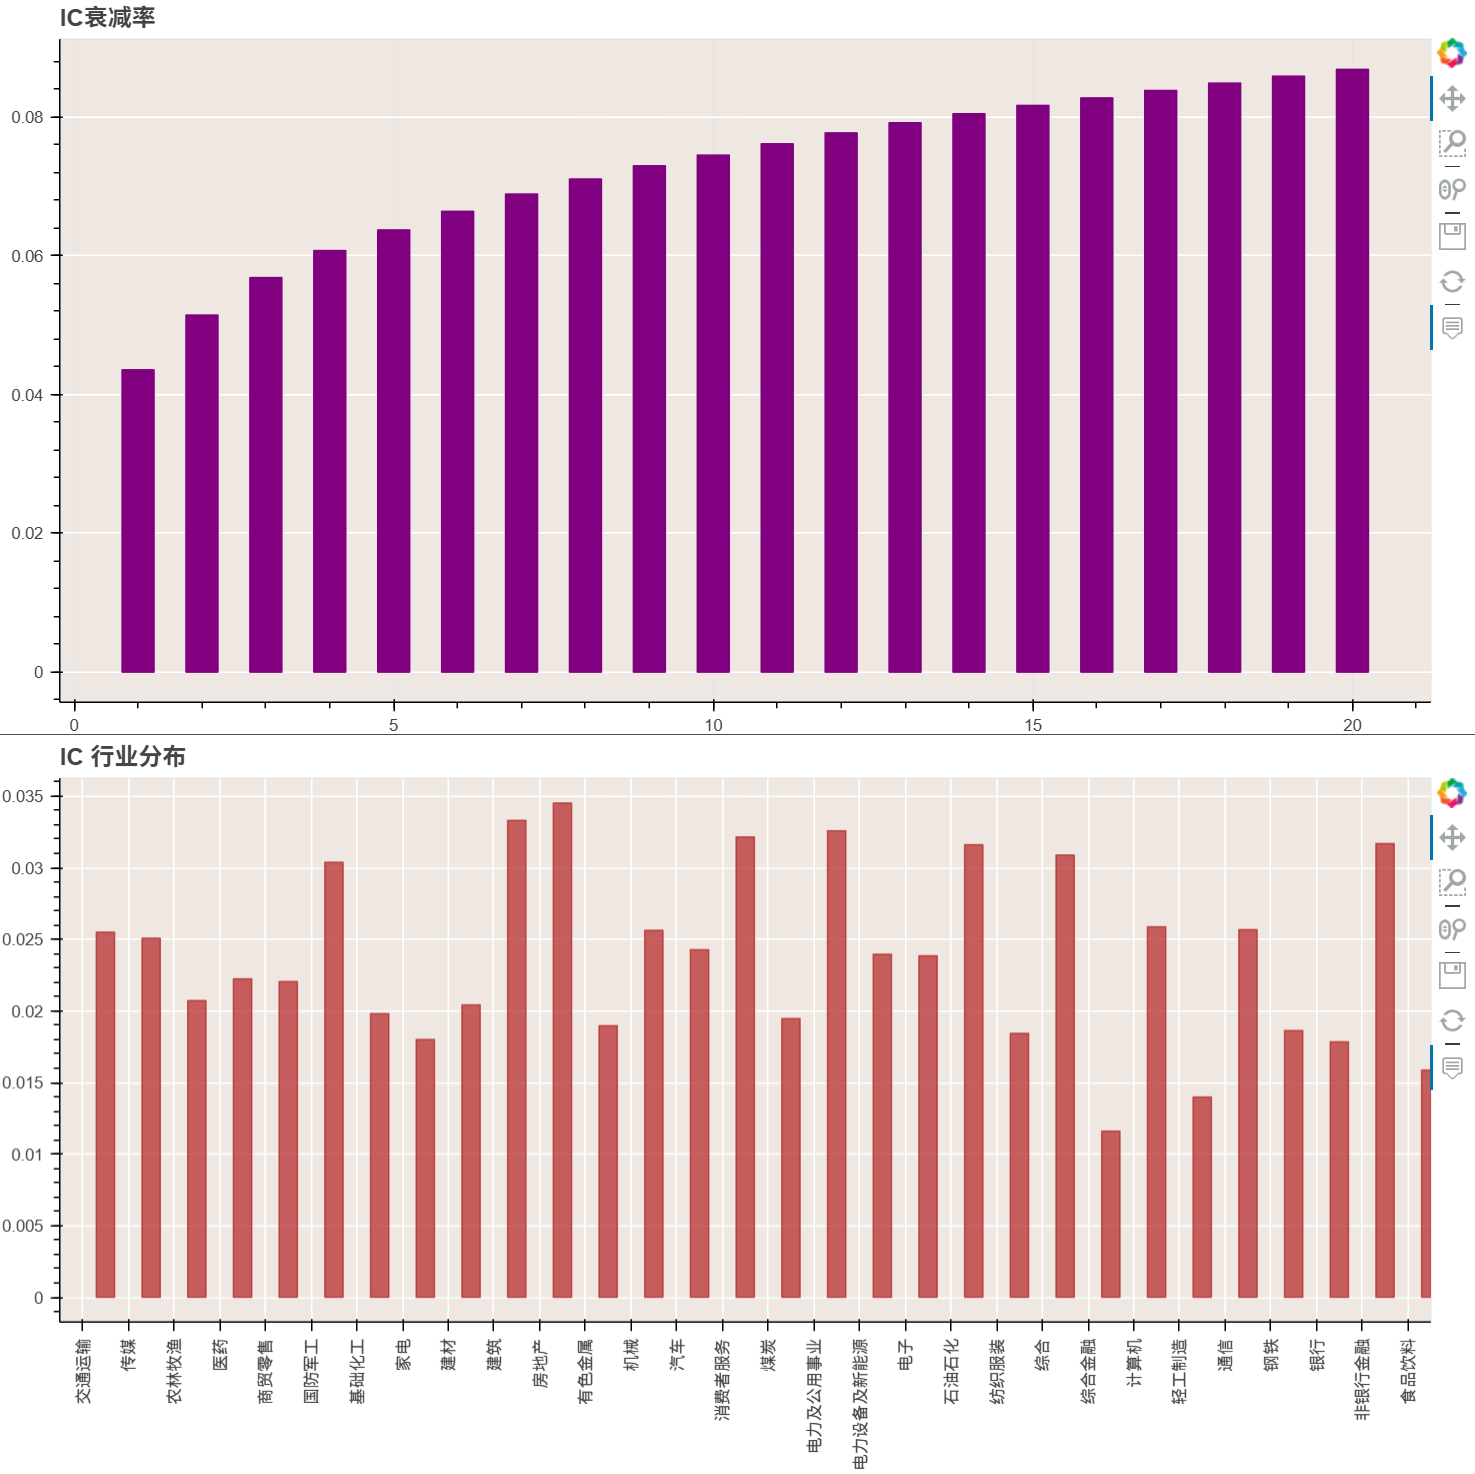

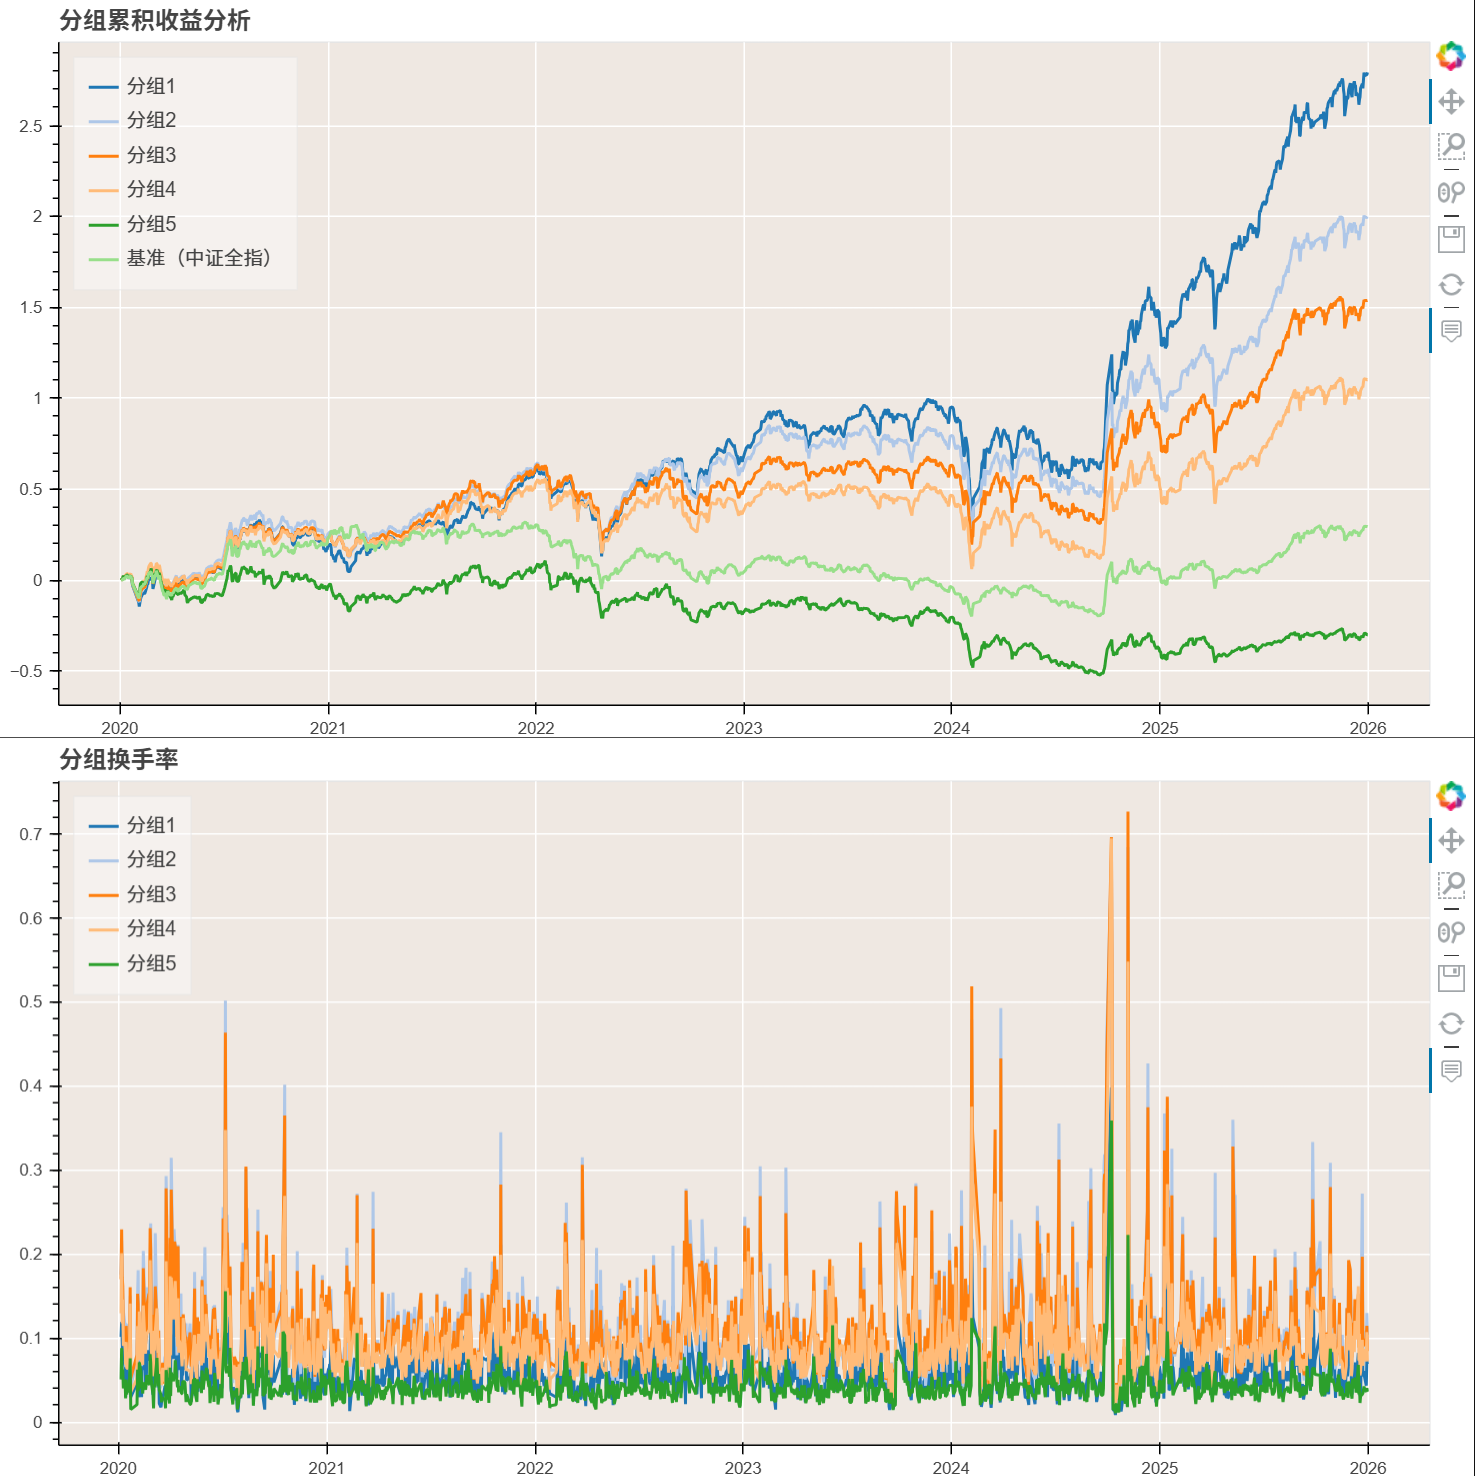

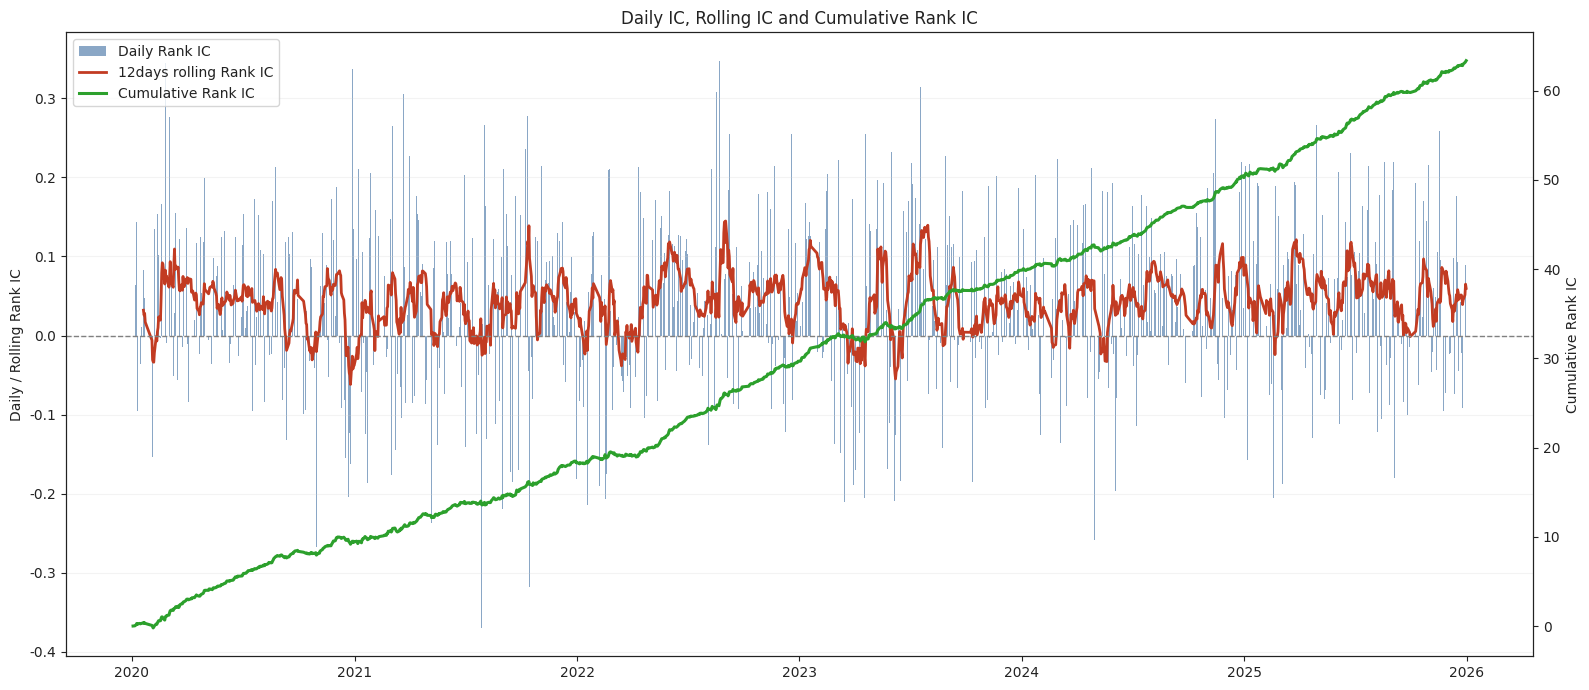

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_abnvold.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

# 每日平均异常成交（ABNVOLAVG）

**行为金融因子 —— 投资者注意力**

$$
\text{ABNVOLAVG} = \frac{1}{m} \sum_{t=1}^{m} \left( \frac{VOL_{i,t}}{\overline{VOL}_{i,t}} \right)
$$

其中：

* $VOL_{i,t}$ 为股票 $i$ 在交易日 $t$ 的成交量；
* $\overline{VOL}_{i,t}$ 为股票 $i$ 在交易日 $t$ 滚动 1 年的平均成交量；
* $m$ 为交易日窗口，一般取为月度。

## 因子说明

每日平均异常成交（ABNVOLAVG）为日频成交量除以过去一年平均成交量的均值，属于**极端交易量类因子**。异常成交量是投资者注意力的常用代理指标之一。因子取值越高，表明该股票在当月平均异常成交水平越高，投资者的关注度也就越高。然而，投资者的注意力是有限的，他们更倾向于交易那些引起自己注意的股票。通常情况下，关注度较高的股票会伴随更多的买入行为。但在 A 股市场中，由于**做多与做空机制不对称**，投资者非理性买入的倾向强于非理性卖出，导致高关注度股票因净买入力量而出现短期价格溢价，这种过度反应往往会在未来引发价格反转。

数据：日度成交量

In [14]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def calculate_abnvolavg_daily(
    start_date,
    end_date,
    short_window=20,
    long_window=250,
    min_active_days=200,
    candidate_ids=None,
    batch_size=500,
):
    """
    ABNVOLAVG_i,T =
    mean_{t=T-short_window+1,...,T}(VOL_i,t / AVG_VOL_i,t)

    AVG_VOL_i,t 为过去 long_window 个市场交易日内，
    有效成交日的平均成交量；至少要求 min_active_days 个有效成交日。
    """
    if min_active_days <= 0 or min_active_days > long_window:
        raise ValueError("min_active_days 必须介于 1 和 long_window 之间。")

    required_lookback = long_window + short_window - 1

    target_dates, volume_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=required_lookback,
    )

    candidate_ids = _get_ids(candidate_ids)
    factor_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        _, volume = _get_batch_close_volume(batch, volume_dates)

        if volume is None:
            continue

        # 仅保留真实成交日的成交量。
        active_volume = volume.where(volume.gt(0))

        # 过去一年中有效成交日的数量。
        active_count = (
            volume.gt(0)
            .rolling(
                window=long_window,
                min_periods=long_window,
            )
            .sum()
            .shift(1)
        )

        # 过去一年有效成交日的平均成交量，不让停牌日的 0 稀释分母。
        active_volume_sum = (
            active_volume.rolling(
                window=long_window,
                min_periods=1,
            )
            .sum()
            .shift(1)
        )

        average_volume = active_volume_sum.div(
            active_count.where(active_count >= min_active_days)
        )

        # 分子、分母都有效时才计算，避免 inf。
        abnormal_volume = (
            volume.div(average_volume)
            .where(volume.gt(0) & average_volume.gt(0))
        )

        factor_wide = abnormal_volume.rolling(
            window=short_window,
            min_periods=short_window,
        ).mean()

        factor_wide = factor_wide.reindex(target_dates)
        factor_parts.append(
            _stack_factor(factor_wide, "ABNVOLAVG")
        )

    if not factor_parts:
        return pd.DataFrame(columns=["ABNVOLAVG"])

    return pd.concat(factor_parts).sort_index()

In [15]:
def exclude_recent_listings(raw_df, min_trading_days=60):
    """剔除上市未满指定交易日的股票因子值。

    以股票上市日为第 0 个交易日；当其后的 ``min_trading_days`` 个交易日均已
    过去，才保留因子。例如 ``min_trading_days=60`` 时，上市后的第 61 个交易日
    起才允许计算因子值。该规则可避免新股上市初期的无涨跌幅限制波动主导排序。

    本函数只过滤最终因子面板；因此可以直接接在
    ``calculate_...(...)`` 后使用。
    """
    if min_trading_days < 0:
        raise ValueError("min_trading_days 不能为负数。")
    if not isinstance(raw_df.index, pd.MultiIndex) or raw_df.index.nlevels != 2:
        raise ValueError("索引必须为两层 MultiIndex：(date, order_book_id)。")

    # 延迟导入，使单纯的数据检查不依赖已初始化的 rqdatac。
    from rqdatac import all_instruments, get_trading_dates

    panel = raw_df.copy()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    signal_dates = pd.DatetimeIndex(panel.index.get_level_values("date"))
    stock_ids = pd.Index(panel.index.get_level_values("order_book_id").unique())

    instruments_df = all_instruments("CS").set_index("order_book_id")
    listed_dates = pd.to_datetime(
        instruments_df["listed_date"].reindex(stock_ids), errors="coerce"
    )
    if listed_dates.isna().any():
        missing_ids = listed_dates[listed_dates.isna()].index.tolist()[:10]
        raise ValueError("以下股票缺少 listed_date：{}".format(missing_ids))

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=signal_dates.max(),
        )
    )
    listing_locs = calendar.searchsorted(listed_dates.to_numpy(), side="left")
    eligible_locs = listing_locs + min_trading_days

    eligible_from_values = np.full(
        len(stock_ids), np.datetime64("NaT"), dtype="datetime64[ns]"
    )
    within_calendar = eligible_locs < len(calendar)
    eligible_from_values[within_calendar] = calendar.to_numpy()[eligible_locs[within_calendar]]
    eligible_from = pd.Series(pd.to_datetime(eligible_from_values), index=stock_ids)

    row_ids = panel.index.get_level_values("order_book_id")
    row_eligible_from = eligible_from.reindex(row_ids).to_numpy()
    keep = signal_dates.to_numpy() >= row_eligible_from
    return panel.loc[keep].sort_index()

In [16]:
abnvolavg_panel = calculate_abnvolavg_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    short_window=20,
    long_window=250,
    min_active_days=200,
)

# 确保新股也有完整的长窗口与短窗口历史。
abnvolavg_panel = exclude_recent_listings(
    abnvolavg_panel,
    min_trading_days=269,
)

abnvolavg_panel.head()

ABNVOLAVG
date       order_book_id           
2020-01-02 000001.XSHE     0.754152
           000002.XSHE     1.775398
           000004.XSHE     1.470728
           000005.XSHE     0.507161
           000006.XSHE     0.680626

,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
实际有效观测数,6.334006e+06,
覆盖股票数,5.279000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0
负值,0.000000e+00,应为 0



最近 5 个交易日的横截面统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99,年份,相对覆盖率
date,,,,,,,,,,,,
2025-12-25,5015,0.935208,0.717585,0.149508,0.740786,8.145961,0.227592,0.312779,2.290115,3.942794,2025,0.996028
2025-12-26,5017,0.943859,0.724884,0.150474,0.741960,7.721274,0.228929,0.317433,2.320830,3.956809,2025,0.996425
2025-12-29,5017,0.944816,0.727334,0.152849,0.741918,7.744166,0.229144,0.317393,2.332430,3.893176,2025,0.996425
2025-12-30,5020,0.950361,0.727473,0.154331,0.747083,7.791694,0.234510,0.322219,2.366788,3.950107,2025,0.997021
2025-12-31,5019,0.950919,0.721852,0.152313,0.750334,7.620316,0.241995,0.325287,2.343496,3.927121,2025,0.996822



因子值最大的 20 条记录：


,date,order_book_id,ABNVOLAVG
391641,2020-06-19,600834.XSHG,18.036130
395145,2020-06-22,600834.XSHG,18.023790
388134,2020-06-18,600834.XSHG,17.983487
384627,2020-06-17,600834.XSHG,17.626031
190360,2020-03-26,002062.XSHE,17.579780
200940,2020-03-31,002062.XSHE,17.498056
186832,2020-03-25,002062.XSHE,17.473736
183305,2020-03-24,002062.XSHE,17.383308
197416,2020-03-30,002062.XSHE,17.270954
204466,2020-04-01,002062.XSHE,17.225544


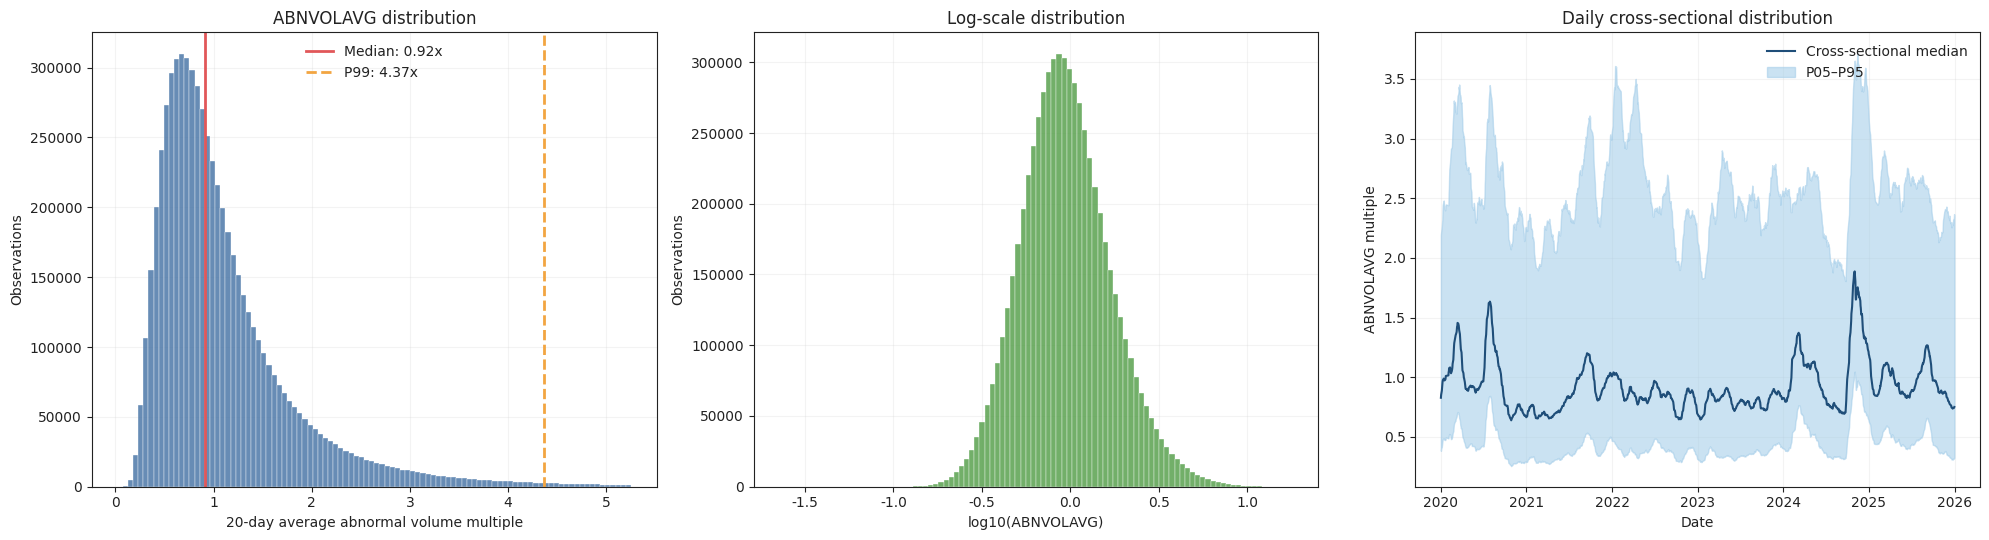

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from rqdatac import all_instruments, get_trading_dates

FACTOR_NAME = "ABNVOLAVG"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"
REQUIRED_HISTORY = 269

panel = abnvolavg_panel.copy()

check_data = pd.DataFrame({
    "date": pd.to_datetime(panel.index.get_level_values("date")),
    "order_book_id": panel.index.get_level_values("order_book_id"),
    FACTOR_NAME: pd.to_numeric(panel[FACTOR_NAME], errors="coerce").values,
})

expected_dates = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=START_DATE,
            end_date=END_DATE,
        )
    )
)

raw_value = check_data[FACTOR_NAME]
is_finite = pd.Series(
    np.isfinite(raw_value.values),
    index=check_data.index,
)
valid = check_data.loc[is_finite & raw_value.gt(0)].copy()

daily = valid.groupby("date")[FACTOR_NAME].agg(
    ["count", "mean", "std", "min", "median", "max"]
)
daily.columns = ["因子股票数", "均值", "标准差", "最小值", "中位数", "最大值"]

daily["P01"] = valid.groupby("date")[FACTOR_NAME].quantile(0.01)
daily["P05"] = valid.groupby("date")[FACTOR_NAME].quantile(0.05)
daily["P95"] = valid.groupby("date")[FACTOR_NAME].quantile(0.95)
daily["P99"] = valid.groupby("date")[FACTOR_NAME].quantile(0.99)

daily = daily.reindex(expected_dates)
daily.index.name = "date"
daily["因子股票数"] = daily["因子股票数"].fillna(0)
daily["年份"] = daily.index.year

year_max = daily.groupby("年份")["因子股票数"].transform("max")
daily["相对覆盖率"] = (
    daily["因子股票数"] / year_max.replace(0, np.nan)
)

stock_days = valid.groupby("order_book_id").size()

# 检查是否有股票在上市历史不足 269 个交易日时产生因子。
first_factor_date = valid.groupby("order_book_id")["date"].min()

instruments_df = (
    all_instruments("CS")
    .drop_duplicates("order_book_id")
    .set_index("order_book_id")
)

listed_dates = pd.to_datetime(
    instruments_df["listed_date"].reindex(first_factor_date.index),
    errors="coerce",
)

calendar = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=listed_dates.min(),
            end_date=END_DATE,
        )
    )
)

listing_locs = calendar.searchsorted(listed_dates.values, side="left")
factor_locs = calendar.searchsorted(first_factor_date.values, side="left")

history_age = pd.Series(
    factor_locs - listing_locs,
    index=first_factor_date.index,
)

early_count = int((history_age < REQUIRED_HISTORY).sum())

summary = pd.DataFrame([
    ["目标交易日数", len(expected_dates), ""],
    ["有至少一个因子值的交易日数", int((daily["因子股票数"] > 0).sum()),
     "应接近目标交易日数"],
    ["完全无输出交易日数", int((daily["因子股票数"] == 0).sum()),
     "应为 0"],
    ["实际有效观测数", len(valid), ""],
    ["覆盖股票数", valid["order_book_id"].nunique(), ""],
    ["重复 date-stock", int(check_data.duplicated(["date", "order_book_id"]).sum()),
     "应为 0"],
    ["显式缺失值", int(raw_value.isna().sum()),
     "最终 stack 后通常应为 0"],
    ["无穷值（inf/-inf）", int(np.isinf(raw_value.values).sum()),
     "应为 0"],
    ["负值", int((raw_value < 0).sum()),
     "应为 0"],
    ["零值", int((raw_value == 0).sum()),
     "应为 0"],
    ["每日因子股票数均值", daily["因子股票数"].mean(), ""],
    ["每日因子股票数 P05", daily["因子股票数"].quantile(0.05),
     "检查低覆盖交易日"],
    ["相对覆盖率 P05", daily["相对覆盖率"].quantile(0.05),
     "建议大于 0.80"],
    ["单股有效天数 P05", stock_days.quantile(0.05), ""],
    ["上市不足 269 日即出现因子的股票数", early_count,
     "应为 0"],
    ["因子均值", valid[FACTOR_NAME].mean(), ""],
    ["因子标准差", valid[FACTOR_NAME].std(), ""],
    ["最小值", valid[FACTOR_NAME].min(),
     "应大于 0；小于 1 并不错误"],
    ["P01", valid[FACTOR_NAME].quantile(0.01), ""],
    ["中位数", valid[FACTOR_NAME].median(),
     "近 20 日平均成交量相对一年均量的倍数"],
    ["P99", valid[FACTOR_NAME].quantile(0.99),
     "检查右尾异常放量"],
    ["最大值", valid[FACTOR_NAME].max(),
     "需复核极端值"],
    ["> 5 倍的观测数", int((valid[FACTOR_NAME] > 5).sum()),
     "人工复核阈值"],
    ["> 10 倍的观测数", int((valid[FACTOR_NAME] > 10).sum()),
     "人工复核阈值"],
    ["> 20 倍的观测数", int((valid[FACTOR_NAME] > 20).sum()),
     "优先复核"],
], columns=["指标", "数值", "判断"])

display(summary.set_index("指标"))

print("\n最近 5 个交易日的横截面统计：")
display(daily.tail())

print("\n因子值最大的 20 条记录：")
display(
    valid.sort_values(FACTOR_NAME, ascending=False)
    .head(20)[["date", "order_book_id", FACTOR_NAME]]
)

# ---------- 白底分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
    "axes.unicode_minus": False,
})

upper = valid[FACTOR_NAME].quantile(0.995)
hist_values = valid.loc[
    valid[FACTOR_NAME] <= upper,
    FACTOR_NAME,
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

axes[0].hist(
    hist_values,
    bins=100,
    color="#4C78A8",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[0].axvline(
    valid[FACTOR_NAME].median(),
    color="#E15759",
    linewidth=2,
    label="Median: {:.2f}x".format(valid[FACTOR_NAME].median()),
)
axes[0].axvline(
    valid[FACTOR_NAME].quantile(0.99),
    color="#F2A541",
    linewidth=2,
    linestyle="--",
    label="P99: {:.2f}x".format(valid[FACTOR_NAME].quantile(0.99)),
)
axes[0].set_title("ABNVOLAVG distribution")
axes[0].set_xlabel("20-day average abnormal volume multiple")
axes[0].set_ylabel("Observations")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

axes[1].hist(
    np.log10(valid[FACTOR_NAME]),
    bins=100,
    color="#59A14F",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[1].set_title("Log-scale distribution")
axes[1].set_xlabel("log10(ABNVOLAVG)")
axes[1].set_ylabel("Observations")
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

plot_daily = daily.dropna(subset=["P05", "中位数", "P95"])

axes[2].fill_between(
    plot_daily.index,
    plot_daily["P05"].values,
    plot_daily["P95"].values,
    color="#A0CBE8",
    alpha=0.55,
    label="P05–P95",
)
axes[2].plot(
    plot_daily.index,
    plot_daily["中位数"].values,
    color="#1F4E79",
    linewidth=1.5,
    label="Cross-sectional median",
)
axes[2].set_title("Daily cross-sectional distribution")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("ABNVOLAVG multiple")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.25)
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.show()

结论：**ABNVOLAVG 已通过完整性、分布与数值合理性检验，可作为原始因子使用。**

- 结构完整：1,455 个交易日均有输出；无重复、缺失、无穷值、负值或零值。
- 历史窗口正确：上市不足 269 个交易日即产生因子的股票数为 0。
- 覆盖稳定：相对覆盖率 P05 为 91.2%，低覆盖日没有断层。
- 分布合理：均值 `1.14`、中位数 `0.92`、P99 `4.37`。均值高于中位数、分布右偏，符合成交量因子的正常特征。
- 2025 年末的截面中位数约 `0.74–0.75`、P99 约 `3.9–4.0`，与全样本水平一致，未出现尾期失真。
- 最大值 `18.04`，虽高但不异常到不可解释；相比旧版 ABNVOLD 的数万倍极端值，修正后的分母已有效消除了停牌零成交量污染。

`ABNVOLAVG=18` 的含义是：过去 20 日内，该股票的平均日成交量约为过去一年有效成交日平均成交量的 18 倍。这比单日放量更强，意味着持续性的高关注度或重大事件期。`600834.XSHG`、`002062.XSHE` 连续多日位于最高值，符合 20 日滚动均值的平滑特征，不是重复数据。

该因子与 ABNVOLD 的区别也很清楚：

- `ABNVOLD`：识别某一天是否出现极端放量。
- `ABNVOLAVG`：识别近一个月是否存在持续性异常放量。

后续用于选股时，可保留原始值；在每日横截面标准化前，可选择 0.5%–99.5% 缩尾，避免极少数持续事件股过度影响组合权重。

In [18]:
# 行：交易日；列：order_book_id；值：ABNRETD
abnvolavg_panel_df = (
    abnvolavg_panel["ABNVOLAVG"]
    .unstack("order_book_id")
    .sort_index()
)

abnvolavg_panel_df.index = pd.to_datetime(abnvolavg_panel_df.index)
abnvolavg_panel_df.columns.name = "order_book_id"

abnvolavg_panel_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,301556.XSHE,301592.XSHE,301626.XSHE,301613.XSHE,688726.XSHG,301628.XSHE,301633.XSHE,603205.XSHG,688750.XSHG,301631.XSHE
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.754152,1.775398,1.470728,0.507161,0.680626,0.536995,1.132942,2.552096,0.439702,0.482977,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.781439,1.813359,1.486021,0.513570,0.727234,0.538661,1.089412,2.772969,0.443089,0.496091,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.788302,1.859447,1.506320,0.526738,0.746505,0.545994,1.043899,2.912830,0.440998,0.519423,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.793875,1.794858,1.518882,0.556402,0.750601,0.506414,0.989302,3.248318,0.517801,0.545148,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.807754,1.774798,1.545388,0.616594,0.772671,0.468682,0.984553,3.506689,0.551313,0.567726,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.719923,1.835793,0.497101,NaN,0.640783,1.930754,0.521326,0.792555,0.527812,0.625229,...,0.758949,0.568761,0.643707,0.332875,1.567999,0.859786,0.380792,0.465299,NaN,NaN
2025-12-26,0.700904,1.770296,0.450271,NaN,0.648750,1.882010,0.507310,0.800093,0.500805,0.594104,...,0.764275,0.625791,0.653390,0.364578,1.675778,0.900252,0.405590,0.454737,1.389199,NaN
2025-12-29,0.684486,1.694574,0.412659,NaN,0.643801,1.822619,0.502577,0.766140,0.476071,0.571554,...,0.750755,0.645085,0.651918,0.373502,1.761845,0.914146,0.461661,0.471898,1.440258,NaN


In [19]:
from rqfactor.notebook import factor_analysis

result_abnvolavg = factor_analysis(
    f=abnvolavg_panel_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_abnvolavg.show()

Loading BokehJS ...

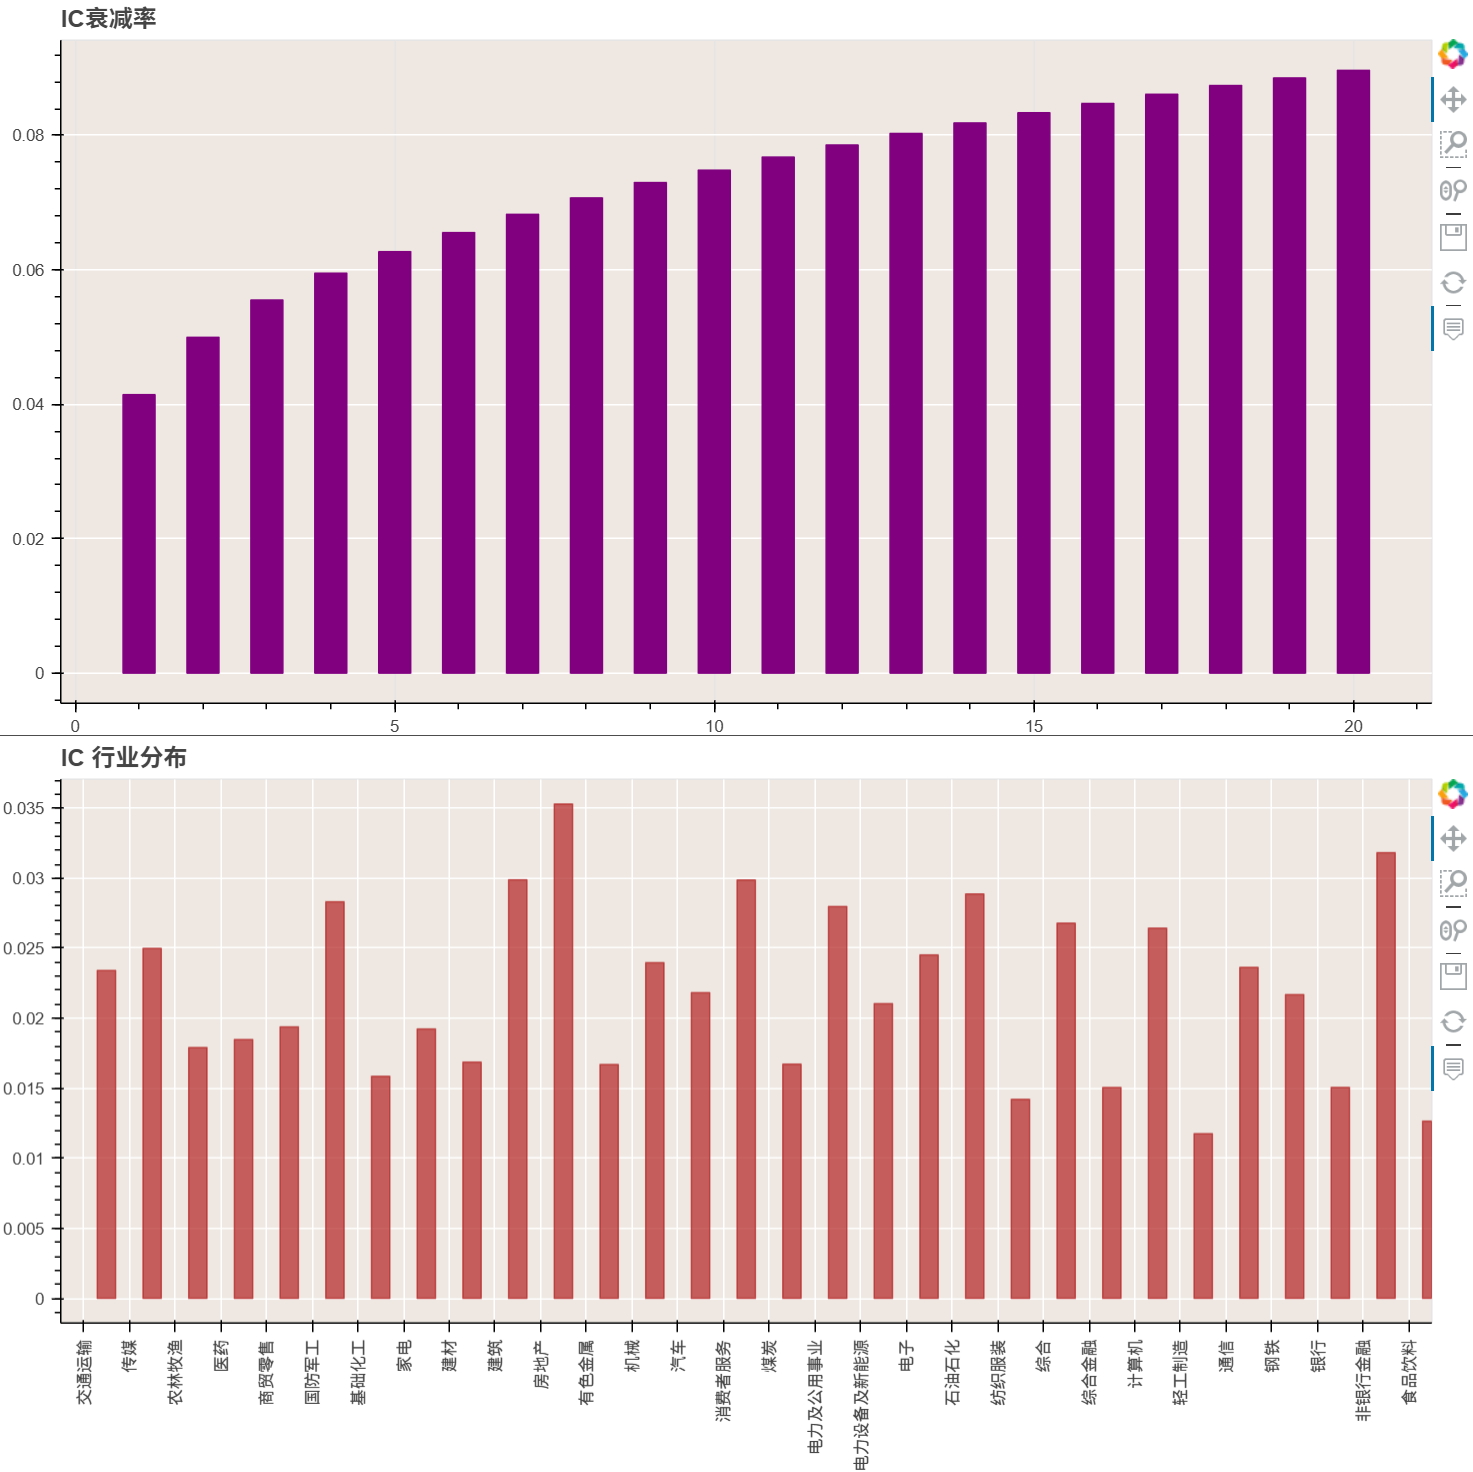

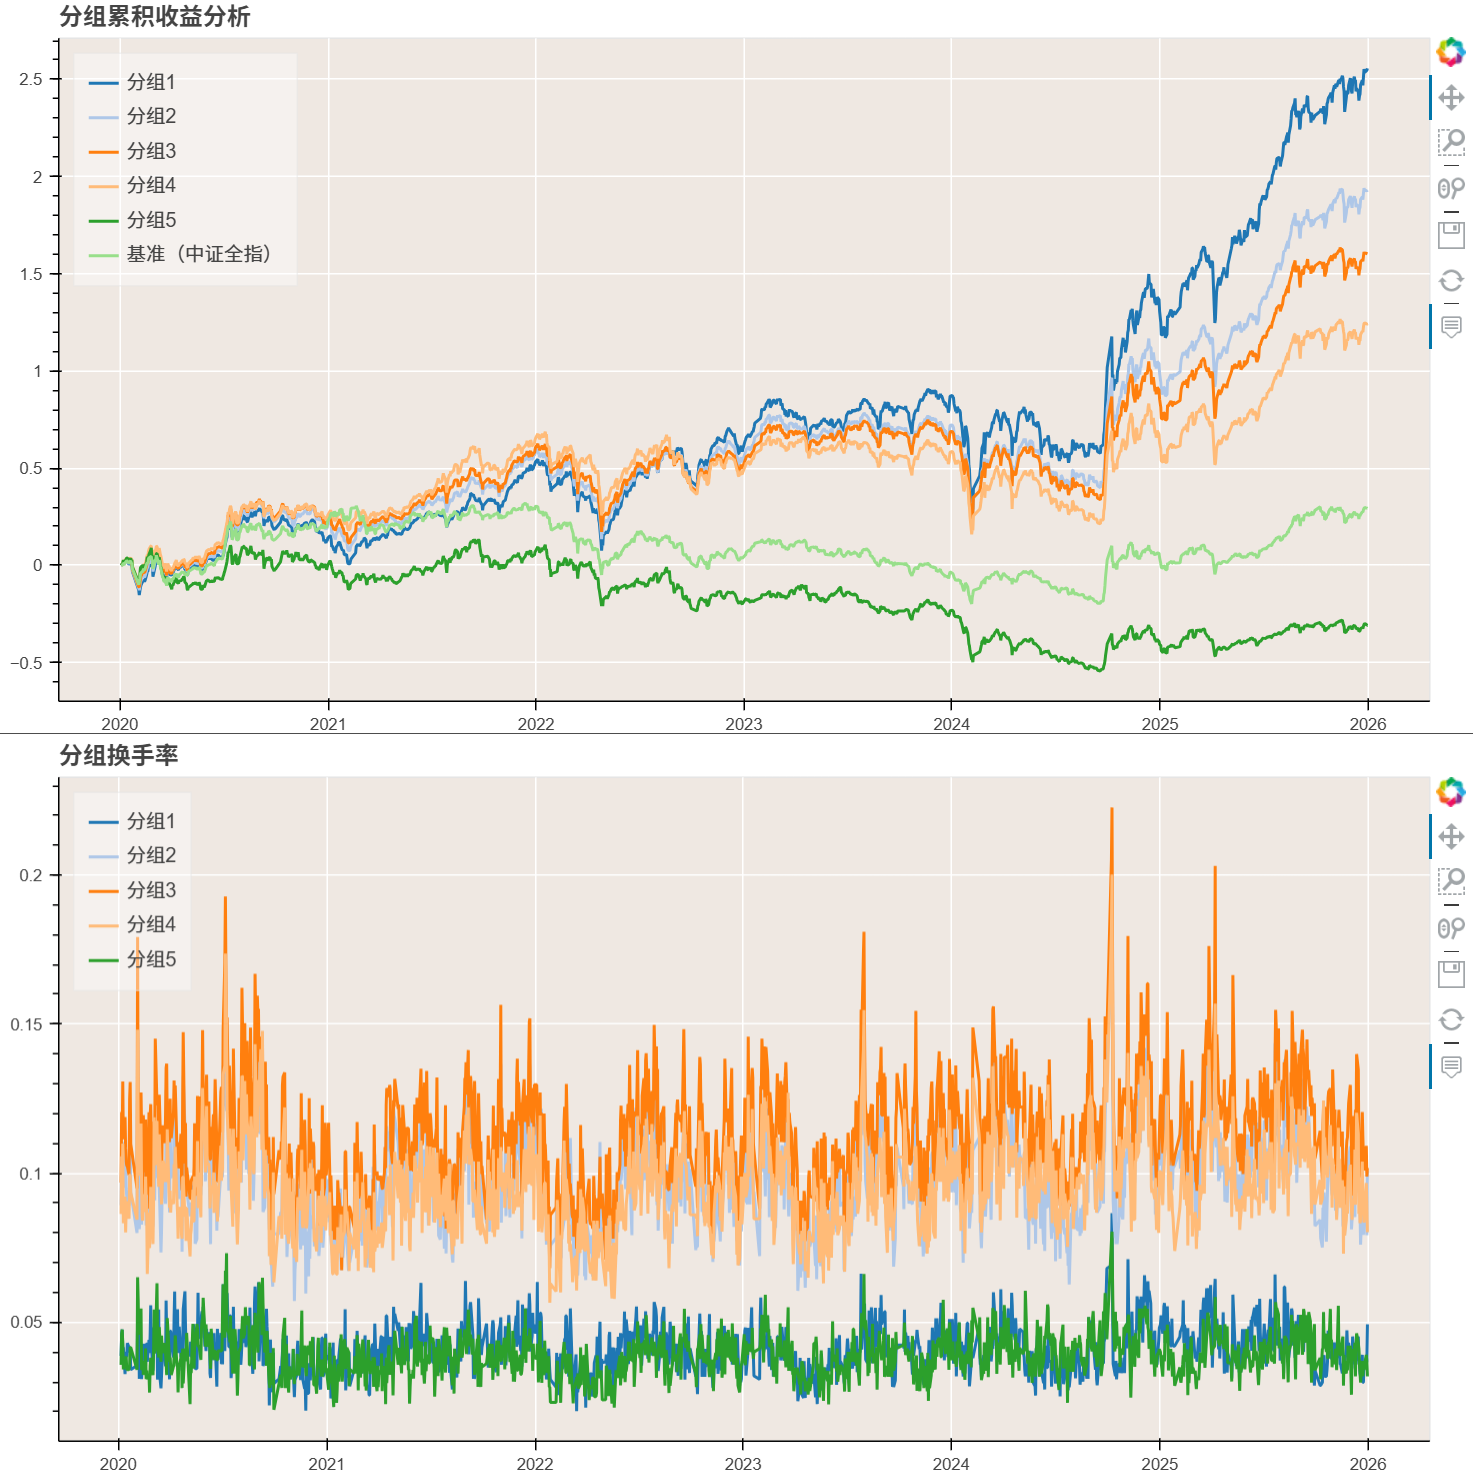

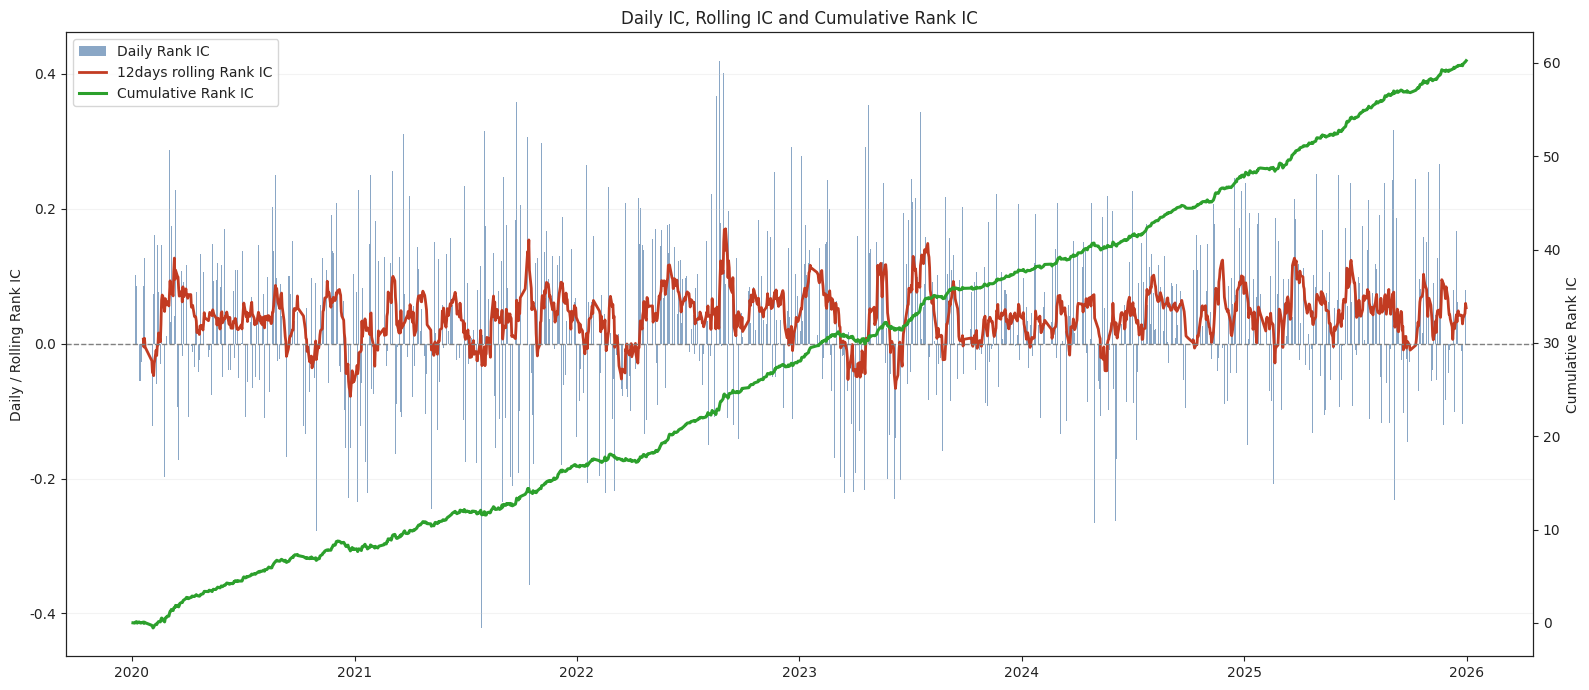

In [20]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_abnvolavg.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()